In [ ]:
all_models = os.listdir(r'/esi/project/niwa00018/rampaln/PUBLICATIONS/2026/CORDEX_ML_TF/Evaluation/diagnostics/)

In [2]:
all_model_names = ['ANN',
 'ANN-orog',
 'CNRM-UNeT',
 'CorrDiff-TW1_NTNU-CWA',
 'CorrDiff-TW1_NTNU-CWA-orog',
 'DeepESD-IFCAv1',
 'DeepESD-IFCAv1-orog',
 'DeepESD_IDL',
 'DeepESDcrps_IFCAv2',
 'DeepESDcrps_IFCAv2-orog',
 'DeepSensor',
 'DeepSensor-orog',
 'DetUNet',
 'DetUNet-orog',
 'DetUNet-v2',
 'DetUNet-v2-orog',
 'EnScale',
 'EnScale-linex',
 'EnScale-orog',
 'FlowMatching-v1',
 'FlowMatching-v1-orog',
 'GNN4CD-orog',
 'ParamDiffusion-orog',
 'ParamUNET',
 'Prithvi-UNet',
 'Prithvi-UNet-orog',
 'RCMFlow-orog',
 'RCMGEM-mv-orog',
 'ResGAN',
 'ResGAN-orog',
 'ResGAN-v2',
 'ResGAN-v2-orog',
 'Rossby-UNet',
 'Rossby-UNet-orog',
 'UiBCorrDiff-orog',
 'ViT-IFCAv1',
 'ViT-IFCAv1-orog',
 'XGBoost_IDL',
 'spaGAN',
 'spaGAN-orog']

In [ ]:
"""
CORDEX-ML-Bench Scorecard  --  RMSE edition
============================================
Three scorecard styles, light->dark grey performance colormap.

  Style 1 -- "all_regions":   per-metric x per-domain (ALPS/NZ/SA/AV) detail
  Style 2 -- "regions_avg":   per-metric, AV column only
  Style 3 -- "overall_rank":  Generative (left) | Deterministic (right),
              4-level column headers, background shading, rotated side labels,
              dashed separator, triangle legend -- matches reference layout.

Fixes
-----
  1. Unique ranks  -- method="average" per-metric, method="first" for display
  2. n_global      -- counts only models with >=1 finite metric value
  3. Grey colormap -- #f5f5f5 (best/lightest) to #1a1a1a (worst/darkest)
  4. Side-by-side  -- Generative | Deterministic in overall rank
  5. Bigger titles -- suptitle 17pt, panel titles 15pt
"""
from __future__ import annotations

import os
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Sequence, Tuple

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import rcParams
from matplotlib.path import Path as MplPath

warnings.filterwarnings("ignore")

rcParams.update({
    "font.family":     "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size":       8.0,
    "axes.linewidth":  0.5,
    "pdf.fonttype":    42,
    "ps.fonttype":     42,
})

# ---------------------------------------------------------------------------
# CONFIG
# ---------------------------------------------------------------------------
DIAG_ROOT       = "/esi/project/niwa00018/rampaln/PUBLICATIONS/2026/CORDEX_ML_TF/Evaluation/diagnostics"
DOMAINS_DEFAULT = ["ALPS_Domain", "NZ_Domain", "SA_Domain"]
OROG_SUFFIX     = "-orog"
SKIP_DIRS       = {".ipynb_checkpoints", "__pycache__", ".git", ".DS_Store",
                   "tmp", "temp"}

GENERATIVE_MODELS = [
    "ResGAN", "ResGAN-v2", "FlowMatching-v1", "CorrDiff-TW1_NTNU-CWA",
    "spaGAN", "ViT-IFCAv1", "EnScale",
    "ParamDiffusion-orog", "RCMGEM-mv-orog", "RCMFlow-orog",
    "UiBCorrDiff-orog", "EnScale-linex",
]
DETERMINISTIC_MODELS = [
    "DetUNet", "DetUNet-v2", "Rossby-UNet", "Prithvi-UNet",
    "DeepESDcrps_IFCAv2", "DeepESD-IFCAv1", "ANN", "CNRM-UNeT",
    "DeepESD_IDL", "ParamUNET", "DeepSensor", "XGBoost_IDL", "GNN4CD-orog",
]
DISPLAY_LABELS: Dict[str, str] = {}

METRICS_PR = {
    "rmse":                "RMSE",
    "mean_bias":           "Mean Bias",
    "sdii_bias":           "SDII",
    "rx1day_bias":         "Rx1day",
    "lag1_corr_bias":      "Lag-1",
    "ralsd":               "RALSD",
    "pr_tasmax_corr_bias": "PR-T",
}
METRICS_TASMAX = {
    "rmse":                "RMSE",
    "mean_bias":           "Mean Bias",
    "txx_bias":            "TXx",
    "lag1_corr_bias":      "Lag-1",
    "ralsd":               "RALSD",
    "pr_tasmax_corr_bias": "PR-T",
    "interannual_var_bias":"IAV",
}

# ---------------------------------------------------------------------------
# COLOURS  -- light->dark grey; grey section headers
# ---------------------------------------------------------------------------
WHITE      = "#ffffff"
BLACK      = "#1a1a1a"
GOLD       = "#d4a017"

HEADER_GEN = "#4a4a4a"   # medium-dark grey for Generative band
HEADER_DET = "#2a2a2a"   # dark grey for Deterministic band
HEADER_OTH = "#222222"

BG_GEN     = "#f2f7f2"   # very pale green tint for generative rows
BG_GEN2    = "#e8f0e8"   # alternating row tint
BG_DET     = "#f4f4f6"   # very pale cool grey for deterministic rows
BG_DET2    = "#ebebf0"   # alternating row tint

LBL_GEN    = "#2d6a2d"   # dark green model labels (generative)
LBL_DET    = "#2a3a6a"   # dark blue model labels (deterministic)

GREY_CMAP = mcolors.LinearSegmentedColormap.from_list(
    "grey_perf",
    ["#f5f5f5", "#e0e0e0", "#cccccc", "#b0b0b0", "#909090",
     "#707070", "#505050", "#383838", "#282828", "#1a1a1a"],
    N=256,
)


def _gc(rank_norm) -> tuple:
    """0 = lightest (best)  ->  1 = darkest (worst)."""
    if rank_norm is None or not np.isfinite(float(rank_norm)):
        return (0.82, 0.82, 0.82, 1.0)
    return GREY_CMAP(float(np.clip(rank_norm, 0.0, 1.0)))


def _tc(rgba) -> str:
    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
    return WHITE if lum < 0.55 else BLACK


def _fmt(v: float) -> str:
    if not np.isfinite(v):
        return ""
    a = abs(v)
    if a < 0.1:  return f"{v:.3f}"
    if a < 10:   return f"{v:.2f}"
    if a < 100:  return f"{v:.1f}"
    return f"{v:.0f}"


# ---------------------------------------------------------------------------
# DATA HELPERS
# ---------------------------------------------------------------------------
def discover_models(root: str) -> List[str]:
    if not os.path.isdir(root):
        return []
    return sorted(
        d for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d))
        and d not in SKIP_DIRS and not d.startswith(".")
    )


def resolve_model_path(root, model, domain, experiment, variable, period):
    is_orog = model.endswith(OROG_SUFFIX)
    base    = model[:-len(OROG_SUFFIX)] if is_orog else model
    orog    = base + OROG_SUFFIX
    bp = os.path.join(root, base, domain, experiment, variable, period)
    op = os.path.join(root, orog, domain, experiment, variable, period)
    if is_orog:
        return op if os.path.isdir(op) else (bp if os.path.isdir(bp) else None)
    return bp if os.path.isdir(bp) else (op if os.path.isdir(op) else None)


def load_scalar(path: str, metric: str) -> float:
    nc = os.path.join(path, f"metric_{metric}.nc")
    if not os.path.exists(nc):
        return np.nan
    try:
        ds = xr.open_dataset(nc)
        if metric in ("psd", "ralsd"):
            return float(ds.RALSD.values)
        if metric in ("pr_tasmax_corr_bias", "PR-T"):
            vals = ds.correlation_bias.values.astype(float).ravel()
        else:
            vals = ds[list(ds.data_vars)[0]].values.astype(float).ravel()
        f = vals[np.isfinite(vals)]
        return float(np.sqrt(np.mean(f ** 2))) if f.size > 0 else np.nan
    except Exception:
        return np.nan


def build_df(root, experiment, variable, period, domains, model_names,
             per_domain=False):
    md       = METRICS_PR if variable == "pr" else METRICS_TASMAX
    ds_short = [d.split("_")[0] for d in domains]

    if not per_domain:
        rec = {}
        for m in model_names:
            row = {}
            for mk, ml in md.items():
                vals = []
                for d in domains:
                    p = resolve_model_path(root, m, d, experiment, variable, period)
                    if p is not None:
                        vals.append(load_scalar(p, mk))
                finite = [v for v in vals if np.isfinite(v)]
                row[ml] = float(np.mean(finite)) if finite else np.nan
            rec[m] = row
        return pd.DataFrame.from_dict(rec, orient="index")

    cols = []
    for ml in md.values():
        for ds in ds_short:
            cols.append((ml, ds))
        cols.append((ml, "AV"))
    mc   = pd.MultiIndex.from_tuples(cols, names=["Metric", "Domain"])
    data = np.full((len(model_names), len(cols)), np.nan)
    for i, m in enumerate(model_names):
        for mi, (mk, ml) in enumerate(md.items()):
            base = mi * (len(ds_short) + 1)
            dv   = []
            for di, d in enumerate(domains):
                p = resolve_model_path(root, m, d, experiment, variable, period)
                v = np.nan if p is None else load_scalar(p, mk)
                data[i, base + di] = v
                if np.isfinite(v):
                    dv.append(v)
            data[i, base + len(ds_short)] = float(np.mean(dv)) if dv else np.nan
    return pd.DataFrame(data, index=list(model_names), columns=mc)


# ---------------------------------------------------------------------------
# RANKING  (Fix 1: unique integers via method="first")
# ---------------------------------------------------------------------------
def _norm_rank(mat: np.ndarray) -> np.ndarray:
    out = np.full_like(mat, np.nan, dtype=float)
    for j in range(mat.shape[1]):
        col = mat[:, j].astype(float)
        r   = pd.Series(col).rank(method="average", ascending=True)
        mr  = np.nanmax(r.values)
        out[:, j] = np.where(
            np.isfinite(col),
            0.0 if (not np.isfinite(mr) or mr <= 1) else (r.values - 1) / (mr - 1),
            np.nan,
        )
    return out


def compute_global_ranks(all_model_names, df_a, df_b, metric_labels):
    def _pmr(df):
        if df is None:
            return pd.DataFrame(np.nan, index=list(all_model_names),
                                columns=list(metric_labels))
        sub = df.reindex(all_model_names)
        return pd.DataFrame({
            c: (sub[c].rank(method="average", ascending=True, na_option="bottom")
                if c in sub.columns
                else pd.Series(np.nan, index=sub.index))
            for c in metric_labels
        })

    pm_a = _pmr(df_a)
    pm_b = _pmr(df_b)

    sum_a = pm_a.mean(axis=1, skipna=True)
    sum_b = (pm_b.mean(axis=1, skipna=True)
             if df_b is not None
             else pd.Series(np.nan, index=sum_a.index))

    ra = sum_a.rank(method="first", ascending=True, na_option="bottom")
    rb = (sum_b.rank(method="first", ascending=True, na_option="bottom")
          if df_b is not None
          else pd.Series(np.nan, index=ra.index))

    combined = (sum_a + sum_b) / 2.0 if df_b is not None else sum_a
    ov = combined.rank(method="first", ascending=True, na_option="bottom")

    gr: Dict[str, Optional[int]] = {}
    pr: Dict[str, Optional[Tuple[int, int]]] = {}
    for m in all_model_names:
        o = ov.get(m, np.nan)
        if np.isfinite(o):
            gr[m] = int(o)
            a, b  = ra.get(m, np.nan), rb.get(m, np.nan)
            pr[m] = (int(a) if np.isfinite(a) else None,
                     int(b) if np.isfinite(b) else None)
        else:
            gr[m] = None
            pr[m] = None
    return gr, pr


# ---------------------------------------------------------------------------
# ROW LAYOUT
# ---------------------------------------------------------------------------
SECTION_H = 0.50
MODEL_H   = 1.0


def build_sorted_rows(available, global_ranks):
    avail = set(available)

    def _rs(m):
        r = global_ranks.get(m) or global_ranks.get(m + OROG_SUFFIX)
        return r or 9999

    def _sg(lst):
        rows = []
        for m in sorted(lst, key=_rs):
            rows.append(dict(kind="model", label=DISPLAY_LABELS.get(m, m),
                             model_name=m, is_orog=False, has_data=(m in avail)))
            orog = m + OROG_SUFFIX
            if not m.endswith(OROG_SUFFIX) and orog in avail:
                rows.append(dict(kind="model",
                                 label=DISPLAY_LABELS.get(orog, orog),
                                 model_name=orog, is_orog=True, has_data=True))
        return rows

    rows  = [dict(kind="section", label="Generative Models",
                  color=HEADER_GEN, model_name=None,
                  is_orog=False, has_data=True)]
    rows += _sg(GENERATIVE_MODELS)
    rows += [dict(kind="section", label="Deterministic Models",
                  color=HEADER_DET, model_name=None,
                  is_orog=False, has_data=True)]
    rows += _sg(DETERMINISTIC_MODELS)

    shown  = {r["model_name"] for r in rows if r["kind"] == "model"}
    extras = sorted(m for m in available if m not in shown)
    if extras:
        rows += [dict(kind="section", label="Other", color=HEADER_OTH,
                      model_name=None, is_orog=False, has_data=True)]
        rows += [dict(kind="model", label=DISPLAY_LABELS.get(m, m),
                      model_name=m, is_orog=False, has_data=True)
                 for m in extras]
    return rows


def _split_by_group(rows):
    gen, det, other = [], [], []
    cur = None
    for r in rows:
        if r["kind"] == "section":
            cur = r["label"]
            continue
        if cur and "Generative" in cur:      gen.append(r)
        elif cur and "Deterministic" in cur: det.append(r)
        else:                                other.append(r)
    if len(gen) <= len(det):
        gen += other
    else:
        det += other
    return gen, det


def row_y_positions(rows):
    total = sum(SECTION_H if r["kind"] == "section" else MODEL_H for r in rows)
    y     = total
    ym    = {}
    for r in rows:
        h = SECTION_H if r["kind"] == "section" else MODEL_H
        y -= h
        if r["kind"] == "model":
            ym[r["model_name"]] = y
    return ym, total


def _flat_y(model_rows):
    total = len(model_rows) * MODEL_H
    ym    = {r["model_name"]: total - (i + 1) * MODEL_H
             for i, r in enumerate(model_rows)}
    return ym, total


# ---------------------------------------------------------------------------
# DRAWING PRIMITIVES
# ---------------------------------------------------------------------------
def _tri(ax, x, y, vn, upper, best=False):
    c     = _gc(vn)
    codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY]
    verts = ([(x, y+1), (x+1, y+1), (x, y), (x, y+1)] if upper
             else [(x+1, y), (x+1, y+1), (x, y), (x+1, y)])
    path  = MplPath(verts, codes)
    ax.add_patch(mpatches.PathPatch(path, fc=c, ec=WHITE, lw=0.3, zorder=2))
    if best:
        ax.add_patch(mpatches.PathPatch(
            path, fc="none", ec=GOLD, lw=1.6,
            joinstyle="round", capstyle="round", zorder=3))
    return c


def _best_mask(nm: np.ndarray) -> np.ndarray:
    mask = np.zeros_like(nm, dtype=bool)
    for j in range(nm.shape[1]):
        col = nm[:, j]
        if np.any(np.isfinite(col)):
            mask[:, j] = (col == np.nanmin(col))
    return mask


def _section_bands(ax, rows, ym, total_w):
    for idx, r in enumerate(rows):
        if r["kind"] != "section":
            continue
        mems = []
        for rr in rows[idx + 1:]:
            if rr["kind"] == "section":
                break
            mems.append(rr["model_name"])
        tops = [ym[m] + MODEL_H for m in mems if m in ym]
        if not tops:
            continue
        yt = max(tops)
        ax.add_patch(plt.Rectangle(
            [0, yt], total_w, SECTION_H,
            fc=r.get("color", HEADER_OTH), ec="none",
            clip_on=False, zorder=4))
        ax.text(0.25, yt + SECTION_H * 0.5, r["label"],
                ha="left", va="center", fontsize=8.5,
                color=WHITE, fontweight="bold", zorder=5, clip_on=False)


def _rlabel(ax, x, y, label, is_orog, no_data, col=None):
    if is_orog:
        ax.text(x, y + 0.5, label, ha="right", va="center",
                fontsize=6.0, color="#888888", style="italic")
    else:
        ax.text(x, y + 0.5, label, ha="right", va="center",
                fontsize=7.2, fontweight="semibold",
                color="#bbbbbb" if no_data else (col or BLACK))


# ---------------------------------------------------------------------------
# STYLE 1 / 2  -- DETAIL PANEL
# ---------------------------------------------------------------------------
def _detail_panel(ax, df_a, df_b, rows, metric_labels, ds_short, per_domain,
                  title, show_labels, ym, total_h, pranks, n_global,
                  lbl_up, lbl_dn, show_rank=True):

    n_m = len(metric_labels)
    sp  = (len(ds_short) + 1) if per_domain else 1
    nc  = n_m * sp
    rw  = 0.95 if show_rank else 0.0

    mr  = [r for r in rows if r["kind"] == "model"]
    mn  = [r["model_name"] for r in mr]

    def _mat(df):
        mat = np.full((len(mn), nc), np.nan)
        if df is None:
            return mat
        for i, m in enumerate(mn):
            if m not in df.index:
                continue
            for mi, ml in enumerate(metric_labels):
                if per_domain:
                    for di, ds in enumerate(ds_short):
                        col = (ml, ds)
                        if col in df.columns:
                            mat[i, mi * sp + di] = df.loc[m, col]
                    ac = (ml, "AV")
                    if ac in df.columns:
                        mat[i, mi * sp + len(ds_short)] = df.loc[m, ac]
                else:
                    if ml in df.columns:
                        mat[i, mi] = df.loc[m, ml]
        return mat

    va = _mat(df_a)
    vb = _mat(df_b) if df_b is not None else None
    na = _norm_rank(va)
    nb = _norm_rank(vb) if vb is not None else None
    ba = _best_mask(na)
    bb = _best_mask(nb) if nb is not None else None

    tw = nc + 0.3 + (rw + 0.3 if show_rank else 0)
    _section_bands(ax, rows, ym, tw)

    for i, r in enumerate(mr):
        m  = r["model_name"]
        if m not in ym:
            continue
        y  = ym[m]
        nd = not r.get("has_data", True)

        for j in range(nc):
            if vb is not None:
                ca = _tri(ax, j, y, na[i, j] if not nd else None,
                          upper=True,  best=bool(ba[i, j]) and not nd)
                cb = _tri(ax, j, y, nb[i, j] if not nd else None,
                          upper=False, best=bool(bb[i, j]) and not nd)
                if not nd and np.isfinite(va[i, j]):
                    ax.text(j + 0.27, y + 0.72, _fmt(va[i, j]),
                            ha="center", va="center", fontsize=4.8,
                            color=_tc(ca), fontfamily="monospace")
                if not nd and np.isfinite(vb[i, j]):
                    ax.text(j + 0.73, y + 0.28, _fmt(vb[i, j]),
                            ha="center", va="center", fontsize=4.8,
                            color=_tc(cb), fontfamily="monospace")
            else:
                c = _gc(na[i, j] if not nd else None)
                ax.add_patch(plt.Rectangle([j, y], 1, MODEL_H,
                                           fc=c, ec=WHITE, lw=0.3, zorder=2))
                if not nd and ba[i, j]:
                    ax.add_patch(plt.Rectangle([j, y], 1, MODEL_H,
                                               fc="none", ec=GOLD, lw=1.6,
                                               joinstyle="round", zorder=3))
                if not nd and np.isfinite(va[i, j]):
                    ax.text(j + 0.5, y + 0.5, _fmt(va[i, j]),
                            ha="center", va="center", fontsize=5.8,
                            color=_tc(c), fontfamily="monospace")

    # Rank column
    if show_rank:
        rx = nc + 0.25
        ma = max((p[0] for p in pranks.values() if p and p[0]), default=1)
        mb = max((p[1] for p in pranks.values() if p and p[1]), default=1)
        for r in mr:
            m = r["model_name"]
            if m not in ym:
                continue
            y    = ym[m]
            pair = pranks.get(m)
            if not pair:
                continue
            a, b = pair
            an   = (a - 1) / max(ma - 1, 1) if a else None
            bn   = (b - 1) / max(mb - 1, 1) if b else None
            if df_b is not None:
                ca = _tri(ax, rx, y, an, upper=True)
                cb = _tri(ax, rx, y, bn, upper=False)
                if a:
                    ax.text(rx + 0.27, y + 0.72, str(a),
                            ha="center", va="center", fontsize=5.6,
                            color=_tc(ca), fontfamily="monospace",
                            fontweight="bold")
                if b:
                    ax.text(rx + 0.73, y + 0.28, str(b),
                            ha="center", va="center", fontsize=5.6,
                            color=_tc(cb), fontfamily="monospace",
                            fontweight="bold")
            else:
                c = _gc(an)
                ax.add_patch(plt.Rectangle([rx, y], rw, MODEL_H,
                                           fc=c, ec=WHITE, lw=0.3, zorder=2))
                if a:
                    ax.text(rx + rw / 2, y + 0.5, str(a),
                            ha="center", va="center", fontsize=6.0,
                            color=_tc(c), fontfamily="monospace",
                            fontweight="bold")

    # Row labels
    if show_labels:
        cc = BLACK
        for r in rows:
            if r["kind"] == "section":
                cc = r.get("color", BLACK)
                continue
            m = r["model_name"]
            if m not in ym:
                continue
            _rlabel(ax, -0.15, ym[m], r["label"], r["is_orog"],
                    not r.get("has_data", True), col=cc)

    # Column headers
    if per_domain:
        for mi in range(n_m):
            base = mi * sp
            for di, ds in enumerate(ds_short):
                ax.text(base + di + 0.5, total_h + 0.02, ds,
                        ha="center", va="bottom", fontsize=5.8, color="#444444")
            ax.text(base + len(ds_short) + 0.5, total_h + 0.02, "AV",
                    ha="center", va="bottom", fontsize=5.8, color="#444444",
                    fontweight="bold")
        for mi, ml in enumerate(metric_labels):
            mid = mi * sp + sp / 2
            ax.text(mid, total_h + SECTION_H + 0.05, ml,
                    ha="center", va="bottom", fontsize=7.2, color=BLACK,
                    fontweight="bold")
            if mi > 0:
                ax.plot([mi * sp, mi * sp], [0, total_h + SECTION_H],
                        color="#cccccc", lw=0.4, zorder=1)
    else:
        for mi, ml in enumerate(metric_labels):
            ax.text(mi + 0.5, total_h + 0.05, ml,
                    ha="left", va="bottom", fontsize=7.2, color=BLACK,
                    fontweight="bold", rotation=45, rotation_mode="anchor")

    if show_rank:
        ax.text(nc + 0.25 + rw / 2, total_h + 0.05, "Rank",
                ha="center", va="bottom", fontsize=7.2, color=BLACK,
                fontweight="bold")

    # Triangle direction legend
    if df_b is not None:
        leg_x, leg_y = 0.10, total_h + SECTION_H + 0.72
        sw = 0.55   # swatch size in data units
        codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY]
        ax.add_patch(mpatches.PathPatch(
            MplPath([(leg_x, leg_y + sw), (leg_x + sw, leg_y + sw),
                     (leg_x, leg_y), (leg_x, leg_y + sw)], codes),
            fc=_gc(0.12), ec=WHITE, lw=0.3, zorder=5, clip_on=False))
        ax.add_patch(mpatches.PathPatch(
            MplPath([(leg_x + sw, leg_y), (leg_x + sw, leg_y + sw),
                     (leg_x, leg_y), (leg_x + sw, leg_y)], codes),
            fc=_gc(0.78), ec=WHITE, lw=0.3, zorder=5, clip_on=False))
        ax.text(leg_x + sw + 0.15, leg_y + sw * 0.72, f"▲  {lbl_up}",
                ha="left", va="center", fontsize=7.5, color=BLACK,
                clip_on=False)
        ax.text(leg_x + sw + 0.15, leg_y + sw * 0.28, f"▽  {lbl_dn}",
                ha="left", va="center", fontsize=7.5, color=BLACK,
                clip_on=False)
 
    ax.set_title(title, fontsize=15, color=BLACK, pad=10, fontweight="bold")
    ax.set_xlim(-0.15, tw)
    ax.set_ylim(-0.15, total_h + SECTION_H + 2.20)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_facecolor(WHITE)


# ---------------------------------------------------------------------------
# STYLE 3  -- helpers for the reference-style overall rank layout
# ---------------------------------------------------------------------------

_COL_HDR_H = 2.70   # total vertical space (data units) above cells for headers


def _draw_col_headers(ax, col_meta: List[dict], total_h: float,
                      accent_color: str):
    """
    4-level column headers matching the reference:
      1. Variable group label + coloured underline
      2. Variable abbreviation
      3. Experiment name
      4. ▲ CV  ▽ Extrap./Interp.
    """
    # Group consecutive columns by variable
    groups: List[Tuple[str, List]] = []
    cur_v, cur_c = None, []
    for ci, meta in enumerate(col_meta):
        v = meta["variable"]
        if v != cur_v:
            if cur_c:
                groups.append((cur_v, cur_c))
            cur_v, cur_c = v, []
        cur_c.append((ci, meta))
    if cur_c:
        groups.append((cur_v, cur_c))

    for var, cols in groups:
        xs     = [ci for ci, _ in cols]
        x_lo   = min(xs)
        x_hi   = max(xs) + 1
        x_mid  = (x_lo + x_hi) / 2.0
        lbl    = ("Precipitation (pr)"
                  if var == "pr" else "Max. Temp. (tasmax)")

        # Level 1 — group label + underline
        y1 = total_h + _COL_HDR_H - 0.18
        ax.text(x_mid, y1, lbl, ha="center", va="bottom",
                fontsize=8.0, color=accent_color, fontweight="bold",
                clip_on=False)
        ax.plot([x_lo + 0.06, x_hi - 0.06], [y1 - 0.04, y1 - 0.04],
                color=accent_color, lw=1.2, clip_on=False)

        # Per-column levels 2-4
        for ci, meta in cols:
            cx = ci + 0.5
            ax.text(cx, total_h + 1.85, meta["variable"],
                    ha="center", va="bottom", fontsize=9.8,
                    color=BLACK, fontweight="bold", clip_on=False)
            ax.text(cx, total_h + 1.18, meta["experiment"],
                    ha="center", va="bottom", fontsize=9.8,
                    color="#444444", clip_on=False)
            ax.text(cx, total_h + 0.55,
                    f"▲ CV  ▽ {meta['lower_label']}",
                    ha="center", va="bottom", fontsize=7,
                    color="#666666", clip_on=False)

        # Dashed separator before each new variable group (except first)
        if groups.index((var, cols)) > 0:
            ax.plot([x_lo, x_lo], [0, total_h + _COL_HDR_H],
                    color="#bbbbbb", lw=0.5, ls="--", zorder=1,
                    clip_on=False)


def _rank_half(ax, model_rows, ym, pair_list, max_rank,
               col_meta, show_labels,
               lbl_color, hdr_color, hdr_label,
               total_h, bg_a, bg_b):
    nc = len(col_meta)
    tw = nc + 0.15

    # Background
    ax.add_patch(plt.Rectangle([0, 0], tw, total_h,
                                fc=bg_a, ec="none", zorder=0))
    for i, r in enumerate(model_rows):
        m = r["model_name"]
        if m not in ym:
            continue
        if i % 2 == 1:
            ax.add_patch(plt.Rectangle([0, ym[m]], tw, MODEL_H,
                                       fc=bg_b, ec="none", zorder=1))

    # Header band
    ax.add_patch(plt.Rectangle([0, total_h], tw, SECTION_H,
                                fc=hdr_color, ec="none",
                                clip_on=False, zorder=4))
    ax.text(tw / 2, total_h + SECTION_H * 0.5, hdr_label,
            ha="center", va="center", fontsize=9.5,
            color=WHITE, fontweight="bold", zorder=5, clip_on=False)

    # Cells
    for ci, pd_ in enumerate(pair_list):
        for r in model_rows:
            m = r["model_name"]
            if m not in ym:
                continue
            y    = ym[m]
            pair = pd_.get(m)
            if pair is None:
                ax.add_patch(plt.Rectangle([ci, y], 1, MODEL_H,
                                           fc=(0.85, 0.85, 0.85, 1),
                                           ec=WHITE, lw=0.3, zorder=2))
                continue
            a, b = pair
            an   = (a - 1) / max(max_rank - 1, 1) if a else None
            bn   = (b - 1) / max(max_rank - 1, 1) if b else None
            ca   = _tri(ax, ci, y, an, upper=True)
            cb   = _tri(ax, ci, y, bn, upper=False)
            if a:
                ax.text(ci + 0.27, y + 0.72, str(a),
                        ha="center", va="center", fontsize=8,
                        color=_tc(ca), fontfamily="monospace",
                        fontweight="bold")
            if b:
                ax.text(ci + 0.73, y + 0.28, str(b),
                        ha="center", va="center", fontsize=8,
                        color=_tc(cb), fontfamily="monospace",
                        fontweight="bold")

    # Vertical grid lines
    for ci in range(1, nc):
        ax.plot([ci, ci], [0, total_h], color="#d8d8d8", lw=0.3, zorder=1)

    # Row labels
    if show_labels:
        for r in model_rows:
            m = r["model_name"]
            if m not in ym:
                continue
            _rlabel(ax, -0.15, ym[m], r["label"], r["is_orog"],
                    not r.get("has_data", True), col=lbl_color)

    # 4-level column headers
    _draw_col_headers(ax, col_meta, total_h, accent_color=hdr_color)

    # Axes
    ax.set_xlim(-0.15, tw)
    ax.set_ylim(-0.15, total_h + SECTION_H + _COL_HDR_H + 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp_ in ax.spines.values():
        sp_.set_visible(False)
    ax.set_facecolor(WHITE)


# ---------------------------------------------------------------------------
# Fix 2  -- n_global
# ---------------------------------------------------------------------------
def _n_with_data(*dfs) -> int:
    s = set()
    for df in dfs:
        if df is None:
            continue
        for m in df.index:
            if np.any(np.isfinite(df.loc[m].values.astype(float))):
                s.add(m)
    return max(len(s), 1)


# ---------------------------------------------------------------------------
# COLORBARS
# ---------------------------------------------------------------------------
def _cbar_metric(fig, x, y, w, h):
    cax = fig.add_axes([x, y, w, h])
    sm  = plt.cm.ScalarMappable(cmap=GREY_CMAP, norm=mcolors.Normalize(0, 1))
    sm.set_array([])
    cb  = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_ticks([0, 1])
    cb.set_ticklabels(["Best", "Worst"])
    cb.ax.tick_params(labelsize=7, length=2, pad=1)
    cb.outline.set_edgecolor("#cccccc")
    cb.outline.set_linewidth(0.4)
    cax.set_title("Metric performance", fontsize=12, pad=2, color=BLACK)


def _cbar_rank(fig, x, y, w, h, n: int):
    cax = fig.add_axes([x, y, w, h])
    sm  = plt.cm.ScalarMappable(cmap=GREY_CMAP, norm=mcolors.Normalize(1, n))
    sm.set_array([])
    cb  = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_ticks([1, n])
    cb.set_ticklabels(["1 (best)", f"{n} (worst)"])
    cb.ax.tick_params(labelsize=15, length=2, pad=1)
    cb.outline.set_edgecolor("#cccccc")
    cb.outline.set_linewidth(0.4)
    cax.set_title("Overall rank", fontsize=13, pad=2, color=BLACK)


# ---------------------------------------------------------------------------
# DATA GATHERING
# ---------------------------------------------------------------------------
def _gather(diag_root, variable, domains,
            esd_exp, esd_pa, esd_pb,
            emu_exp, emu_pa, emu_pb, per_domain):
    available = discover_models(diag_root)
    md        = METRICS_PR if variable == "pr" else METRICS_TASMAX
    mls       = list(md.values())
    registry  = GENERATIVE_MODELS + DETERMINISTIC_MODELS
    orog_v    = [m + OROG_SUFFIX for m in registry if not m.endswith(OROG_SUFFIX)]
    all_names = list(dict.fromkeys(registry + orog_v + available))

    def _bdf(exp, p, pd_=per_domain):
        if not (exp and p):
            return None
        z1 = build_df(diag_root, exp, variable, p, domains, all_names,
                        per_domain=pd_)
        return z1.loc[all_model_names]
        
        #     def bdf(exp, p):
#         z1 = build_df(diag_root, exp, variable, p, domains, all_names,
#                         per_domain=per_domain) if exp and p else None
#         return z1.loc[all_model_names]
#     def bdf_f(exp, p):
#         z1 = build_df(diag_root, exp, variable, p, domains, all_names) \
#             if exp and p else None
#         return z1.loc[all_model_names]

    da_a = _bdf(esd_exp, esd_pa);  da_b = _bdf(esd_exp, esd_pb)
    du_a = _bdf(emu_exp, emu_pa);  du_b = _bdf(emu_exp, emu_pb)

    if per_domain:
        fa_a = _bdf(esd_exp, esd_pa, False)
        fa_b = _bdf(esd_exp, esd_pb, False)
        fu_a = _bdf(emu_exp, emu_pa, False)
        fu_b = _bdf(emu_exp, emu_pb, False)
    else:
        fa_a, fa_b, fu_a, fu_b = da_a, da_b, du_a, du_b

    _none = {m: None for m in all_names}
    ge, pe = (compute_global_ranks(all_names, fa_a, fa_b, mls)
              if fa_a is not None else (_none.copy(), _none.copy()))
    gu, pu = (compute_global_ranks(all_names, fu_a, fu_b, mls)
              if fu_a is not None else (_none.copy(), _none.copy()))

    return dict(
        available=available,
        all_model_names=all_names,
        metric_labels=mls,
        df_esd_a=da_a, df_esd_b=da_b,
        df_emu_a=du_a, df_emu_b=du_b,
        grank_esd=ge, prank_esd=pe,
        grank_emu=gu, prank_emu=pu,
        n_global=_n_with_data(fa_a, fa_b, fu_a, fu_b),
    )


# ---------------------------------------------------------------------------
# MAIN PLOT FUNCTIONS
# ---------------------------------------------------------------------------
def _dual_panels(data, variable, domains, per_domain,
                 save_path, figsize, style_label):
    mls = data["metric_labels"]
    ds  = [d.split("_")[0] for d in domains]
    sr  = (data["grank_esd"]
           if any(v is not None for v in data["grank_esd"].values())
           else data["grank_emu"])
    rows = build_sorted_rows(data["available"], sr)
    ym, th = row_y_positions(rows)

    sp  = (len(ds) + 1) if per_domain else 1
    nc  = len(mls) * sp
    cw  = 0.50 if per_domain else 0.75
    lw  = 2.4;  pw = nc * cw + 1.8;  gw = 0.7
    he  = data["df_esd_a"] is not None
    hu  = data["df_emu_a"] is not None
    np_ = int(he) + int(hu)
    tw  = lw + pw * np_ + gw * max(np_ - 1, 0) + 0.3
    th_ = th * 0.36 + 3.8

    fig = plt.figure(figsize=figsize or (tw, th_), facecolor=WHITE)
    fig.patch.set_facecolor(WHITE)

    lf = lw / tw;  pf = pw / tw;  gf = gw / tw
    bot, top = 0.07, 0.88
    #top = 1.38
    cx = lf

    if he:
        _detail_panel(fig.add_axes([cx, bot, pf, top - bot]),
                      data["df_esd_a"], data["df_esd_b"],
                      rows, mls, ds, per_domain,
                      "ESD", True, ym, th,
                      data["prank_esd"], data["n_global"],
                      "Cross-validation", "Extrapolation")
        cx += pf + gf

    if hu:
        _detail_panel(fig.add_axes([cx, bot, pf, top - bot]),
                      data["df_emu_a"], data["df_emu_b"],
                      rows, mls, ds, per_domain,
                      "Emulator Hist-Future", not he, ym, th,
                      data["prank_emu"], data["n_global"],
                      "Cross-validation", "Interpolation")

    vl = "Precipitation (pr)" if variable == "pr" else "Max Temperature (tasmax)"
    fig.suptitle(
        f"CORDEX-ML-Bench Scorecard  ·  RMSE  |  {vl} ",
        fontsize=20, color=BLACK, fontweight="bold", y =0.955)

    #_cbar_metric(fig, 0.20, 0.028, 0.27, 0.011)
    _cbar_rank(fig,   0.2, 0.028, 0.6, 0.011, data["n_global"])
    fig.text(0.50, 0.007,
             f"Gold = best per metric  ·  "
             f"Rank across {data['n_global']} models with data  ·  "
             "RMSE = sqrt(mean($x^2$))",
             ha="center", va="center", fontsize=9.5,
             color="#555555", style="italic")

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
        print(f"Saved -> {save_path}")
    return fig


def _overall_rank(datasets, save_path, figsize):
    """
    Generative (left) | Deterministic (right) overall rank summary.
    Matches reference layout: 4-level column headers, background shading,
    rotated side labels, dashed separator, triangle legend.
    """
    primary = datasets[0][1]
    avail   = sorted(set().union(*(d["available"] for _, d in datasets)))
    sr      = (primary["grank_esd"]
               if any(v is not None for v in primary["grank_esd"].values())
               else primary["grank_emu"])
    rows    = build_sorted_rows(avail, sr)
 
    pair_list: List[dict] = []
    col_meta:  List[dict] = []
    ng = 1
    for var, d in datasets:
        if any(v is not None for v in d["prank_esd"].values()):
            pair_list.append(d["prank_esd"])
            col_meta.append(dict(variable=var, experiment="ESD",
                                 lower_label="Extrap."))
        if any(v is not None for v in d["prank_emu"].values()):
            pair_list.append(d["prank_emu"])
            col_meta.append(dict(variable=var, experiment="Emulator",
                                 lower_label="Interp."))
        ng = max(ng, d["n_global"])
 
    if not col_meta:
        raise ValueError("No experiments with data for overall rank summary.")
 
    max_rank = max(
        (r for pd_ in pair_list for v in pd_.values()
         if v for r in v if r),
        default=1,
    )
 
    gen, det = _split_by_group(rows)
    gy, gh   = _flat_y(gen)
    dy, dh   = _flat_y(det)
 
    nc      = len(col_meta)
    cell_w  = 0.85          # slightly narrower when 4 cols to keep figure width sane
    lbl_w   = 2.00    # space for row labels
    panel_w = nc * cell_w + 0.25
    gap_w   = 1.20    # space between the two halves
 
    fig_w = lbl_w * 2 + panel_w * 2 + gap_w + 0.8
    fig_h = max(gh, dh) * 0.32 + 5.0
 
    fig = plt.figure(figsize=figsize or (fig_w, fig_h), facecolor=WHITE)
    fig.patch.set_facecolor(WHITE)
    fig.suptitle("CORDEX-ML-Bench  —  Overall Rank Summary",
                 fontsize=17, color=BLACK, fontweight="bold", y=0.972)
 
    bot, top = 0.13, 0.88
 
    # Axes in figure-fraction coordinates
    #   Generative: labels on left, cells next
    #   Deterministic: gap, then labels, cells
    gen_lbl_f  = lbl_w / fig_w
    gen_cell_f = panel_w / fig_w
    det_left_f = (lbl_w + panel_w + gap_w) / fig_w
    det_cell_f = panel_w / fig_w
 
    ax_g = fig.add_axes([gen_lbl_f,                 bot, gen_cell_f, top - bot])
    ax_d = fig.add_axes([det_left_f + lbl_w/fig_w,  bot, det_cell_f, top - bot])
 
    _rank_half(ax_g, gen, gy, pair_list, max_rank, col_meta,
               show_labels=True,
               lbl_color=LBL_GEN, hdr_color=HEADER_GEN,
               hdr_label="Generative Models",
               total_h=gh, bg_a=BG_GEN, bg_b=BG_GEN2)
 
    _rank_half(ax_d, det, dy, pair_list, max_rank, col_meta,
               show_labels=True,
               lbl_color=LBL_DET, hdr_color=HEADER_DET,
               hdr_label="Deterministic Models",
               total_h=dh, bg_a=BG_DET, bg_b=BG_DET2)
 
    # Rotated section labels on outer edges
    fig.text(0.010, (bot + top) / 2, "GENERATIVE",
             rotation=90, ha="center", va="center",
             fontsize=9.5, color=HEADER_GEN, fontweight="bold")
    fig.text(det_left_f - 0.012, (bot + top) / 2, "DETERMINISTIC",
             rotation=90, ha="center", va="center",
             fontsize=9.5, color=HEADER_DET, fontweight="bold")
 
    # Dashed vertical separator
    sep_x = (gen_lbl_f + gen_cell_f + det_left_f) / 2
    fig.add_artist(plt.Line2D(
        [sep_x, sep_x], [bot + 0.01, top - 0.01],
        transform=fig.transFigure,
        color="#999999", lw=1.0, ls="--", zorder=10))
 
    # Colorbar (bottom-left)
    _cbar_rank(fig, 0.05, 0.045, 0.38, 0.015, ng)
 
    # Legend with triangle swatch (bottom-right)
    la = fig.add_axes([0.56, 0.022, 0.40, 0.072])
    la.set_xlim(0, 1);  la.set_ylim(0, 1);  la.axis("off")
    codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY]
    sw = 0.075
    la.add_patch(mpatches.PathPatch(
        MplPath([(0.01, 0.90), (sw + 0.01, 0.90), (0.01, 0.10), (0.01, 0.90)],
                codes),
        fc=_gc(0.08), ec=WHITE, lw=0.6, transform=la.transAxes, zorder=2))
    la.add_patch(mpatches.PathPatch(
        MplPath([(sw + 0.01, 0.90), (sw + 0.01, 0.10), (0.01, 0.10),
                 (sw + 0.01, 0.90)], codes),
        fc=_gc(0.62), ec=WHITE, lw=0.6, transform=la.transAxes, zorder=2))
    la.text(sw + 0.06, 0.70,
            "▲  upper-left  =  Cross-validation rank",
            ha="left", va="center", fontsize=8.5, color=BLACK,
            transform=la.transAxes)
    la.text(sw + 0.06, 0.28,
            "▽  lower-right  =  Extrapolation / Interpolation rank",
            ha="left", va="center", fontsize=8.5, color=BLACK,
            transform=la.transAxes)
 
    fig.text(0.50, 0.006,
             f"Rank across {ng} models with data  ·  "
             "method='first': ties broken by list order  ·  "
             "RMSE = sqrt(mean(x^2))",
             ha="center", va="center", fontsize=6.5,
             color="#555555", style="italic")
 
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
        print(f"Saved -> {save_path}")
    return fig

# ---------------------------------------------------------------------------
# PUBLIC API
# ---------------------------------------------------------------------------
def plot_scorecard_all_regions(
    variable="pr", diag_root=DIAG_ROOT, domains=None,
    esd_experiment="ESD_pseudo_reality",
    esd_period_a="Perfect_cross_validation",
    esd_period_b="Perfect_extrapolation",
    emu_experiment="Emulator_hist_future",
    emu_period_a="Perfect_cross_validation",
    emu_period_b="Perfect_interpolation",
    save_path=None, figsize=None,
) -> plt.Figure:
    """STYLE 1 -- per-domain detail (ALPS / NZ / SA / AV)."""
    domains = domains or DOMAINS_DEFAULT
    print(f"[Style 1: all regions] variable={variable!r}")
    d = _gather(diag_root, variable, domains,
                esd_experiment, esd_period_a, esd_period_b,
                emu_experiment, emu_period_a, emu_period_b,
                per_domain=True)
    return _dual_panels(d, variable, domains, True, save_path, figsize,
                        "")


def plot_scorecard_regions_avg(
    variable="pr", diag_root=DIAG_ROOT, domains=None,
    esd_experiment="ESD_pseudo_reality",
    esd_period_a="Perfect_cross_validation",
    esd_period_b="Perfect_extrapolation",
    emu_experiment="Emulator_hist_future",
    emu_period_a="Perfect_cross_validation",
    emu_period_b="Perfect_interpolation",
    save_path=None, figsize=None,
) -> plt.Figure:
    """STYLE 2 -- region-averaged (one AV value per metric)."""
    domains = domains or DOMAINS_DEFAULT
    print(f"[Style 2: regions avg] variable={variable!r}")
    d = _gather(diag_root, variable, domains,
                esd_experiment, esd_period_a, esd_period_b,
                emu_experiment, emu_period_a, emu_period_b,
                per_domain=False)
    return _dual_panels(d, variable, domains, False, save_path, figsize,
                        " ")


def plot_scorecard_overall_rank(
    variable="pr", diag_root=DIAG_ROOT, domains=None,
    esd_experiment="ESD_pseudo_reality",
    esd_period_a="Perfect_cross_validation",
    esd_period_b="Perfect_extrapolation",
    emu_experiment="Emulator_hist_future",
    emu_period_a="Perfect_cross_validation",
    emu_period_b="Perfect_interpolation",
    save_path=None, figsize=None,
) -> plt.Figure:
    """STYLE 3 -- side-by-side Generative | Deterministic overall rank."""
    domains = domains or DOMAINS_DEFAULT
    print(f"[Style 3: overall rank] variable={variable!r}")
    d = _gather(diag_root, variable, domains,
                esd_experiment, esd_period_a, esd_period_b,
                emu_experiment, emu_period_a, emu_period_b,
                per_domain=False)
    return _overall_rank([(variable, d)], save_path=save_path, figsize=figsize)

def plot_scorecard_combined_rank(
    diag_root=DIAG_ROOT, domains=None,
    esd_experiment="ESD_pseudo_reality",
    esd_period_a="Perfect_cross_validation",
    esd_period_b="Perfect_extrapolation",
    emu_experiment="Emulator_hist_future",
    emu_period_a="Perfect_cross_validation",
    emu_period_b="Perfect_interpolation",
    save_path=None, figsize=None,
) -> plt.Figure:
    """STYLE 3 (combined) -- pr + tasmax in one figure, 4 columns per half.
 
    Matches the reference layout exactly: Precipitation (pr) and
    Max. Temp. (tasmax) columns grouped side-by-side within each half.
    """
    domains = domains or DOMAINS_DEFAULT
    print("[Style 3: combined rank] pr + tasmax")
    d_pr     = _gather(diag_root, "pr", domains,
                       esd_experiment, esd_period_a, esd_period_b,
                       emu_experiment, emu_period_a, emu_period_b,
                       per_domain=False)
    d_tasmax = _gather(diag_root, "tasmax", domains,
                       esd_experiment, esd_period_a, esd_period_b,
                       emu_experiment, emu_period_a, emu_period_b,
                       per_domain=False)
    return _overall_rank([("pr", d_pr), ("tasmax", d_tasmax)],
                         save_path=save_path, figsize=figsize)
# ---------------------------------------------------------------------------
# ENTRY POINT
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    out = Path("./scorecards")
    out.mkdir(exist_ok=True)

    for var in ("pr", "tasmax"):
        plot_scorecard_all_regions(
            variable=var,
            save_path=str(out / f"scorecard_{var}_all_regions.pdf"))
        plt.close("all")

        plot_scorecard_regions_avg(
            variable=var,
            save_path=str(out / f"scorecard_{var}_regions_avg.pdf"))
        plot_scorecard_combined_rank(
        save_path=str(out / "scorecard_combined_overall_rank.pdf"))
        plt.close("all")
        

# plot_scorecard_overall_rank(
#     variable=var,
#     save_path=str(out / f"scorecard_{var}_overall_rank.pdf"))
#plt.close("all")

[Style 1: all regions] variable='pr'


In [59]:
# """
# CORDEX-ML-Bench Scorecard  --  RMSE edition
# ============================================
# Three scorecard styles, light->dark grey performance colormap.

#   Style 1 -- "all_regions":   per-metric x per-domain (ALPS/NZ/SA/AV) detail
#   Style 2 -- "regions_avg":   per-metric, AV column only
#   Style 3 -- "overall_rank":  Generative (left) | Deterministic (right) side-by-side

# Fixes applied
# -------------
#   1. Duplicate rankings -- method="average" per-metric, method="first" for final
#      display -> every model gets a unique integer, no gaps, no duplicates.
#   2. n_global -- counts only models that actually have >=1 finite metric value.
#   3. Grey colormap -- light (#f5f5f5) = best, dark (#1a1a1a) = worst.
#   4. Overall rank -- side-by-side Generative | Deterministic layout.
# """

# from __future__ import annotations

# import os
# import warnings
# from pathlib import Path
# from typing import Dict, List, Optional, Sequence, Tuple

# import matplotlib.colors as mcolors
# import matplotlib.patches as mpatches
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# import xarray as xr
# from matplotlib import rcParams
# from matplotlib.path import Path as MplPath

# warnings.filterwarnings("ignore")

# rcParams.update({
#     "font.family":     "sans-serif",
#     "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
#     "font.size":       7.5,
#     "axes.linewidth":  0.5,
#     "pdf.fonttype":    42,
#     "ps.fonttype":     42,
# })

# # ---------------------------------------------------------------------------
# # CONFIG
# # ---------------------------------------------------------------------------

# DIAG_ROOT       = "./diagnostics"
# DOMAINS_DEFAULT = ["ALPS_Domain", "NZ_Domain", "SA_Domain"]
# OROG_SUFFIX     = "-orog"
# SKIP_DIRS       = {".ipynb_checkpoints", "__pycache__", ".git", ".DS_Store",
#                    "tmp", "temp"}

# GENERATIVE_MODELS = [
#     "ResGAN", "ResGAN-v2", "FlowMatching-v1", "CorrDiff-TW1_NTNU-CWA",
#     "spaGAN", "ViT-IFCAv1", "EnScale",
#     "ParamDiffusion-orog", "RCMGEM-mv-orog", "RCMFlow-orog",
#     "UiBCorrDiff-orog", "EnScale-linex",
# ]

# DETERMINISTIC_MODELS = [
#     "DetUNet", "DetUNet-v2", "Rossby-UNet", "Prithvi-UNet",
#     "DeepESDcrps_IFCAv2", "DeepESD-IFCAv1", "ANN", "CNRM-UNeT",
#     "DeepESD_IDL", "ParamUNET", "DeepSensor", "XGBoost_IDL", "GNN4CD-orog",
# ]

# DISPLAY_LABELS: Dict[str, str] = {}

# METRICS_PR = {
#     "rmse":                "RMSE",
#     "mean_bias":           "Mean Bias",
#     "sdii_bias":           "SDII",
#     "rx1day_bias":         "Rx1day",
#     "lag1_corr_bias":      "Lag-1",
#     "ralsd":               "RALSD",
#     "pr_tasmax_corr_bias": "PR-T",
# }
# METRICS_TASMAX = {
#     "rmse":                "RMSE",
#     "mean_bias":           "Mean Bias",
#     "txx_bias":            "TXx",
#     "lag1_corr_bias":      "Lag-1",
#     "ralsd":               "RALSD",
#     "pr_tasmax_corr_bias": "PR-T",
#     "interannual_var_bias":"IAV",
# }

# all_model_names =  ['ANN',
#  'ANN-orog',
#  'CNRM-UNeT',
#  'CorrDiff-TW1_NTNU-CWA',
#  'CorrDiff-TW1_NTNU-CWA-orog',
#  'DeepESD-IFCAv1',
#  'DeepESD-IFCAv1-orog',
#  'DeepESD_IDL',
#  'DeepESDcrps_IFCAv2',
#  'DeepESDcrps_IFCAv2-orog',
#  'DeepSensor',
#  'DeepSensor-orog',
#  'DetUNet',
#  'DetUNet-orog',
#  'DetUNet-v2',
#  'DetUNet-v2-orog',
#  'EnScale',
#  'EnScale-linex',
#  'EnScale-orog',
#  'FlowMatching-v1',
#  'FlowMatching-v1-orog',
#  'GNN4CD-orog',
#  'ParamDiffusion-orog',
#  'ParamUNET',
#  'Prithvi-UNet',
#  'Prithvi-UNet-orog',
#  'RCMFlow-orog',
#  'RCMGEM-mv-orog',
#  'ResGAN',
#  'ResGAN-orog',
#  'ResGAN-v2',
#  'ResGAN-v2-orog',
#  'Rossby-UNet',
#  'Rossby-UNet-orog',
#  'UiBCorrDiff-orog',
#  'ViT-IFCAv1',
#  'ViT-IFCAv1-orog',
#  'XGBoost_IDL',
#  'spaGAN',
#  'spaGAN-orog']
# # ---------------------------------------------------------------------------
# # FIX 3 -- COLOURS: light->dark grey; grey section headers
# # ---------------------------------------------------------------------------

# WHITE      = "#ffffff"
# BLACK      = "#1a1a1a"
# HEADER_GEN = "#555555"
# HEADER_DET = "#333333"
# HEADER_OTH = "#222222"
# GOLD       = "#d4a017"

# GREY_CMAP = mcolors.LinearSegmentedColormap.from_list(
#     "grey_scale",
#     ["#f5f5f5", "#e0e0e0", "#cccccc", "#b0b0b0", "#909090",
#      "#707070", "#505050", "#383838", "#282828", "#1a1a1a"],
#     N=256,
# )


# def _gc(rank_norm):
#     if rank_norm is None or not np.isfinite(float(rank_norm)):
#         return (0.80, 0.80, 0.80, 1.0)
#     return GREY_CMAP(float(np.clip(rank_norm, 0, 1)))


# def _tc(rgba) -> str:
#     return WHITE if (0.299*rgba[0] + 0.587*rgba[1] + 0.114*rgba[2]) < 0.55 else BLACK


# def _fmt(v):
#     if not np.isfinite(v): return ""
#     a = abs(v)
#     if a < 0.1: return f"{v:.3f}"
#     if a < 10:  return f"{v:.2f}"
#     if a < 100: return f"{v:.1f}"
#     return f"{v:.0f}"

# # ---------------------------------------------------------------------------
# # DATA HELPERS
# # ---------------------------------------------------------------------------

# def discover_models(root: str) -> List[str]:
#     if not os.path.isdir(root):
#         return []
#     return sorted(d for d in os.listdir(root)
#                   if os.path.isdir(os.path.join(root, d))
#                   and d not in SKIP_DIRS and not d.startswith("."))


# def resolve_model_path(root, model, domain, experiment, variable, period):
#     is_orog = model.endswith(OROG_SUFFIX)
#     base = model[:-len(OROG_SUFFIX)] if is_orog else model
#     orog = base + OROG_SUFFIX
#     bp = os.path.join(root, base, domain, experiment, variable, period)
#     op = os.path.join(root, orog, domain, experiment, variable, period)
#     if is_orog:
#         return op if os.path.isdir(op) else (bp if os.path.isdir(bp) else None)
#     return bp if os.path.isdir(bp) else (op if os.path.isdir(op) else None)


# def load_scalar(path, metric) -> float:
#     nc = os.path.join(path, f"metric_{metric}.nc")
#     if not os.path.exists(nc):
#         return np.nan
#     try:
#         ds = xr.open_dataset(nc)
#         if metric in ("psd", "ralsd"):
#             return float(ds.RALSD.values)
#         if metric in ("pr_tasmax_corr_bias", "PR-T"):
#             vals = ds.correlation_bias.values.astype(float).ravel()
#         else:
#             vals = ds[list(ds.data_vars)[0]].values.astype(float).ravel()
#         f = vals#[np.isfinite(vals)]
#         return float(np.sqrt(np.nanmean(f**2))) if f.size > 0 else np.nan
#         #float(np.sqrt(np.nanmean(diff ** 2)))
#     except Exception:
#         return np.nan


# def build_df(root, experiment, variable, period, domains, model_names,
#              per_domain=False):
#     md = METRICS_PR if variable == "pr" else METRICS_TASMAX
#     ds_short = [d.split("_")[0] for d in domains]

#     if not per_domain:
#         rec = {}
#         for m in model_names:
#             row = {}
#             for mk, ml in md.items():
#                 vals = [load_scalar(p, mk)
#                         for d in domains
#                         for p in [resolve_model_path(root, m, d, experiment,
#                                                      variable, period)]
#                         if p is not None]
#                 row[ml] = float(np.mean([v for v in vals if np.isfinite(v)])) \
#                     if any(np.isfinite(v) for v in vals) else np.nan
#             rec[m] = row
#         return pd.DataFrame.from_dict(rec, orient="index")

#     cols = [(ml, ds) for ml in md.values() for ds in ds_short] + \
#            [(ml, "AV") for ml in md.values()]
#     # rebuild properly ordered
#     cols = []
#     for ml in md.values():
#         for ds in ds_short: cols.append((ml, ds))
#         cols.append((ml, "AV"))
#     mc = pd.MultiIndex.from_tuples(cols, names=["Metric", "Domain"])
#     data = np.full((len(model_names), len(cols)), np.nan)
#     for i, m in enumerate(model_names):
#         for mi, (mk, ml) in enumerate(md.items()):
#             base = mi * (len(ds_short) + 1)
#             dv = []
#             for di, d in enumerate(domains):
#                 p = resolve_model_path(root, m, d, experiment, variable, period)
#                 v = np.nan if p is None else load_scalar(p, mk)
#                 data[i, base + di] = v
#                 if np.isfinite(v): dv.append(v)
#             data[i, base + len(ds_short)] = float(np.mean(dv)) if dv else np.nan
#     return pd.DataFrame(data, index=list(model_names), columns=mc)

# # ---------------------------------------------------------------------------
# # FIX 1 -- RANKING
# # ---------------------------------------------------------------------------

# def _norm_rank(mat):
#     out = np.full_like(mat, np.nan, dtype=float)
#     for j in range(mat.shape[1]):
#         col = mat[:, j].astype(float)
#         r = pd.Series(col).rank(method="average", ascending=True)
#         mr = np.nanmax(r.values)
#         out[:, j] = np.where(np.isfinite(col),
#                              0.0 if (not np.isfinite(mr) or mr <= 1)
#                              else (r.values - 1) / (mr - 1),
#                              np.nan)
#     return out


# def compute_global_ranks(all_model_names, df_a, df_b, metric_labels):
#     def _pmr(df):
#         if df is None:
#             return pd.DataFrame(np.nan, index=list(all_model_names),
#                                 columns=list(metric_labels))
#         sub = df.reindex(all_model_names)
#         return pd.DataFrame({
#             c: (sub[c].rank(method="average", ascending=True, na_option="bottom")
#                 if c in sub.columns
#                 else pd.Series(np.nan, index=sub.index))
#             for c in metric_labels
#         })

#     pm_a = _pmr(df_a); pm_b = _pmr(df_b)
#     sum_a = pm_a.mean(axis=1, skipna=True)
#     sum_b = (pm_b.mean(axis=1, skipna=True) if df_b is not None
#              else pd.Series(np.nan, index=sum_a.index))
#     # method="first" -> unique integers, no duplicates
#     ra = sum_a.rank(method="first", ascending=True, na_option="bottom")
#     rb = (sum_b.rank(method="first", ascending=True, na_option="bottom")
#           if df_b is not None else pd.Series(np.nan, index=ra.index))
#     print(ra, sum_a)
#     combined = (sum_a + sum_b) / 2.0 if df_b is not None else sum_a
#     ov = combined.rank(method="first", ascending=True, na_option="bottom")

#     gr, pr = {}, {}
#     for m in all_model_names:
#         o = ov.get(m, np.nan)
#         if np.isfinite(o):
#             gr[m] = int(o)
#             a, b = ra.get(m, np.nan), rb.get(m, np.nan)
#             pr[m] = (int(a) if np.isfinite(a) else None,
#                      int(b) if np.isfinite(b) else None)
#         else:
#             gr[m] = None; pr[m] = None
#     return gr, pr

# # ---------------------------------------------------------------------------
# # ROW LAYOUT
# # ---------------------------------------------------------------------------

# SECTION_H = 0.55
# MODEL_H   = 1.0


# def build_sorted_rows(available, global_ranks):
#     avail = set(available)

#     def _rs(m):
#         r = global_ranks.get(m) or global_ranks.get(m + OROG_SUFFIX)
#         return r or 9999

#     def _sg(lst):
#         rows = []
#         for m in sorted(lst, key=_rs):
#             rows.append(dict(kind="model", label=DISPLAY_LABELS.get(m, m),
#                              model_name=m, is_orog=False, has_data=(m in avail)))
#             orog = m + OROG_SUFFIX
#             if not m.endswith(OROG_SUFFIX) and orog in avail:
#                 rows.append(dict(kind="model",
#                                  label=DISPLAY_LABELS.get(orog, orog),
#                                  model_name=orog, is_orog=True, has_data=True))
#         return rows

#     rows = [dict(kind="section", label="Generative Models", color=HEADER_GEN,
#                  model_name=None, is_orog=False, has_data=True)]
#     rows += _sg(GENERATIVE_MODELS)
#     rows += [dict(kind="section", label="Deterministic Models", color=HEADER_DET,
#                   model_name=None, is_orog=False, has_data=True)]
#     rows += _sg(DETERMINISTIC_MODELS)

#     shown = {r["model_name"] for r in rows if r["kind"] == "model"}
#     extras = sorted(m for m in available if m not in shown)
#     if extras:
#         rows += [dict(kind="section", label="Other", color=HEADER_OTH,
#                       model_name=None, is_orog=False, has_data=True)]
#         rows += [dict(kind="model", label=DISPLAY_LABELS.get(m, m),
#                       model_name=m, is_orog=False, has_data=True)
#                  for m in extras]
#     return rows


# def _split_by_group(rows):
#     gen, det, other = [], [], []
#     cur = None
#     for r in rows:
#         if r["kind"] == "section": cur = r["label"]; continue
#         if cur and "Generative" in cur: gen.append(r)
#         elif cur and "Deterministic" in cur: det.append(r)
#         else: other.append(r)
#     if len(gen) <= len(det): gen += other
#     else: det += other
#     return gen, det


# def row_y_positions(rows):
#     total = sum(SECTION_H if r["kind"] == "section" else MODEL_H for r in rows)
#     y = total; ym = {}
#     for r in rows:
#         h = SECTION_H if r["kind"] == "section" else MODEL_H
#         y -= h
#         if r["kind"] == "model": ym[r["model_name"]] = y
#     return ym, total


# def _flat_y(model_rows):
#     total = len(model_rows) * MODEL_H
#     ym = {r["model_name"]: total - (i+1)*MODEL_H
#           for i, r in enumerate(model_rows)}
#     return ym, total

# # ---------------------------------------------------------------------------
# # DRAWING PRIMITIVES
# # ---------------------------------------------------------------------------

# def _tri(ax, x, y, vn, upper, best=False):
#     c = _gc(vn)
#     codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY]
#     v = ([(x,y+1),(x+1,y+1),(x,y),(x,y+1)] if upper
#          else [(x+1,y),(x+1,y+1),(x,y),(x+1,y)])
#     p = MplPath(v, codes)
#     ax.add_patch(mpatches.PathPatch(p, fc=c, ec=WHITE, lw=0.3, zorder=2))
#     if best:
#         ax.add_patch(mpatches.PathPatch(p, fc="none", ec=GOLD, lw=1.6,
#                                         joinstyle="round", capstyle="round",
#                                         zorder=3))
#     return c


# def _best_mask(nm):
#     mask = np.zeros_like(nm, dtype=bool)
#     for j in range(nm.shape[1]):
#         col = nm[:, j]
#         if np.any(np.isfinite(col)): mask[:, j] = col == np.nanmin(col)
#     return mask


# def _section_bands(ax, rows, ym, total_w):
#     for idx, r in enumerate(rows):
#         if r["kind"] != "section": continue
#         mems = []
#         for rr in rows[idx+1:]:
#             if rr["kind"] == "section": break
#             mems.append(rr["model_name"])
#         tops = [ym[m] + MODEL_H for m in mems if m in ym]
#         if not tops: continue
#         yt = max(tops)
#         ax.add_patch(plt.Rectangle([0, yt], total_w, SECTION_H,
#                                    fc=r.get("color", HEADER_OTH),
#                                    ec="none", clip_on=False, zorder=4))
#         ax.text(0.25, yt + SECTION_H*0.5, r["label"],
#                 ha="left", va="center", fontsize=8, color=WHITE,
#                 fontweight="bold", zorder=5, clip_on=False)


# def _rlabel(ax, x, y, label, is_orog, no_data, col=None):
#     if is_orog:
#         ax.text(x, y+0.5, label, ha="right", va="center",
#                 fontsize=5.8, color="#888888", style="italic")
#     else:
#         ax.text(x, y+0.5, label, ha="right", va="center",
#                 fontsize=6.8, color="#bbbbbb" if no_data else (col or BLACK),
#                 fontweight="semibold")

# # ---------------------------------------------------------------------------
# # STYLE 1 / 2 -- DETAIL PANEL
# # ---------------------------------------------------------------------------

# def _detail_panel(ax, df_a, df_b, rows, metric_labels, ds_short, per_domain,
#                   title, show_labels, ym, total_h, pranks, n_global,
#                   lbl_up, lbl_dn, show_rank=True):
#     n_m = len(metric_labels)
#     sp  = (len(ds_short) + 1) if per_domain else 1
#     nc  = n_m * sp
#     rw  = 0.95 if show_rank else 0.0
#     mr  = [r for r in rows if r["kind"] == "model"]
#     mn  = [r["model_name"] for r in mr]

#     def _mat(df):
#         mat = np.full((len(mn), nc), np.nan)
#         if df is None: return mat
#         for i, m in enumerate(mn):
#             if m not in df.index: continue
#             for mi, ml in enumerate(metric_labels):
#                 if per_domain:
#                     for di, ds in enumerate(ds_short):
#                         col = (ml, ds)
#                         if col in df.columns:
#                             mat[i, mi*sp+di] = df.loc[m, col]
#                     ac = (ml, "AV")
#                     if ac in df.columns:
#                         mat[i, mi*sp+len(ds_short)] = df.loc[m, ac]
#                 else:
#                     if ml in df.columns: mat[i, mi] = df.loc[m, ml]
#         return mat

#     va = _mat(df_a); vb = _mat(df_b) if df_b is not None else None
#     na = _norm_rank(va); nb = _norm_rank(vb) if vb is not None else None
#     ba = _best_mask(na); bb = _best_mask(nb) if nb is not None else None

#     tw = nc + 0.3 + (rw + 0.3 if show_rank else 0)
#     _section_bands(ax, rows, ym, tw)

#     for i, r in enumerate(mr):
#         m = r["model_name"]
#         if m not in ym: continue
#         y = ym[m]; nd = not r.get("has_data", True)
#         for j in range(nc):
#             if vb is not None:
#                 ca = _tri(ax, j, y, na[i,j] if not nd else None,
#                           upper=True, best=bool(ba[i,j]) and not nd)
#                 cb = _tri(ax, j, y, nb[i,j] if not nd else None,
#                           upper=False, best=bool(bb[i,j]) and not nd)
#                 if not nd and np.isfinite(va[i,j]):
#                     ax.text(j+0.27, y+0.72, _fmt(va[i,j]),
#                             ha="center", va="center", fontsize=4.7,
#                             color=_tc(ca), fontfamily="monospace")
#                 if not nd and np.isfinite(vb[i,j]):
#                     ax.text(j+0.73, y+0.28, _fmt(vb[i,j]),
#                             ha="center", va="center", fontsize=4.7,
#                             color=_tc(cb), fontfamily="monospace")
#             else:
#                 c = _gc(na[i,j] if not nd else None)
#                 ax.add_patch(plt.Rectangle([j, y], 1, MODEL_H,
#                                            fc=c, ec=WHITE, lw=0.3, zorder=2))
#                 if not nd and ba[i,j]:
#                     ax.add_patch(plt.Rectangle([j, y], 1, MODEL_H,
#                                                fc="none", ec=GOLD, lw=1.6,
#                                                joinstyle="round", zorder=3))
#                 if not nd and np.isfinite(va[i,j]):
#                     ax.text(j+0.5, y+0.5, _fmt(va[i,j]),
#                             ha="center", va="center", fontsize=5.6,
#                             color=_tc(c), fontfamily="monospace")

#     if show_rank:
#         rx = nc + 0.25
#         ma = max((p[0] for p in pranks.values() if p and p[0]), default=1)
#         mb = max((p[1] for p in pranks.values() if p and p[1]), default=1)
#         for r in mr:
#             m = r["model_name"]
#             if m not in ym: continue
#             y = ym[m]; pair = pranks.get(m)
#             if not pair: continue
#             a, b = pair
#             an = (a-1)/max(ma-1,1) if a else None
#             bn = (b-1)/max(mb-1,1) if b else None
#             if df_b is not None:
#                 ca = _tri(ax, rx, y, an, upper=True)
#                 cb = _tri(ax, rx, y, bn, upper=False)
#                 if a: ax.text(rx+0.27, y+0.72, str(a), ha="center", va="center",
#                               fontsize=5.4, color=_tc(ca), fontfamily="monospace",
#                               fontweight="bold")
#                 if b: ax.text(rx+0.73, y+0.28, str(b), ha="center", va="center",
#                               fontsize=5.4, color=_tc(cb), fontfamily="monospace",
#                               fontweight="bold")
#             else:
#                 c = _gc(an)
#                 ax.add_patch(plt.Rectangle([rx,y], rw, MODEL_H,
#                                            fc=c, ec=WHITE, lw=0.3, zorder=2))
#                 if a: ax.text(rx+rw/2, y+0.5, str(a), ha="center", va="center",
#                               fontsize=5.8, color=_tc(c), fontfamily="monospace",
#                               fontweight="bold")

#     if show_labels:
#         cc = BLACK
#         for r in rows:
#             if r["kind"] == "section": cc = r.get("color", BLACK); continue
#             m = r["model_name"]
#             if m not in ym: continue
#             _rlabel(ax, -0.15, ym[m], r["label"], r["is_orog"],
#                     not r.get("has_data", True), col=cc)

#     if per_domain:
#         for mi in range(n_m):
#             base = mi * sp
#             for di, ds in enumerate(ds_short):
#                 ax.text(base+di+0.5, total_h+0.02, ds, ha="center", va="bottom",
#                         fontsize=5.5, color="#444444")
#             ax.text(base+len(ds_short)+0.5, total_h+0.02, "AV",
#                     ha="center", va="bottom", fontsize=5.5, color="#444444",
#                     fontweight="bold")
#         for mi, ml in enumerate(metric_labels):
#             ax.text(mi*sp + sp/2, total_h+SECTION_H+0.05, ml,
#                     ha="center", va="bottom", fontsize=6.8, color=BLACK,
#                     fontweight="bold")
#             if mi > 0:
#                 ax.plot([mi*sp, mi*sp], [0, total_h+SECTION_H],
#                         color="#cccccc", lw=0.4, zorder=1)
#     else:
#         for mi, ml in enumerate(metric_labels):
#             ax.text(mi+0.5, total_h+0.05, ml, ha="left", va="bottom",
#                     fontsize=6.8, color=BLACK, fontweight="bold",
#                     rotation=45, rotation_mode="anchor")

#     if show_rank:
#         ax.text(nc+0.25+rw/2, total_h+0.05, "Rank",
#                 ha="center", va="bottom", fontsize=6.8, color=BLACK,
#                 fontweight="bold")

#     ax.set_title(title, fontsize=14, color=BLACK, pad=8, fontweight="bold")
#     ax.set_xlim(-0.15, tw); ax.set_ylim(-0.15, total_h+SECTION_H+1.9)
#     ax.set_xticks([]); ax.set_yticks([])
#     for sp_ in ax.spines.values(): sp_.set_visible(False)
#     ax.set_facecolor(WHITE)

# # ---------------------------------------------------------------------------
# # FIX 4 -- STYLE 3: side-by-side Generative | Deterministic
# # ---------------------------------------------------------------------------

# def _rank_half(ax, model_rows, ym, pair_list, max_rank, nc,
#                show_labels, lbl_col, hdr_col, hdr_label, total_h, col_meta):
#     tw = nc + 0.3
#     ax.add_patch(plt.Rectangle([0, total_h], tw, SECTION_H,
#                                 fc=hdr_col, ec="none", clip_on=False, zorder=4))
#     ax.text(0.20, total_h+SECTION_H*0.5, hdr_label,
#             ha="left", va="center", fontsize=7.5, color=WHITE,
#             fontweight="bold", zorder=5, clip_on=False)

#     for i, r in enumerate(model_rows):
#         m = r["model_name"]
#         if m not in ym: continue
#         if i % 2 == 0:
#             ax.add_patch(plt.Rectangle([0, ym[m]], tw, MODEL_H,
#                                        fc="#f8f8f8", ec="none", zorder=1))

#     for ci, pd_ in enumerate(pair_list):
#         for r in model_rows:
#             m = r["model_name"]
#             if m not in ym: continue
#             y = ym[m]; pair = pd_.get(m)
#             if pair is None:
#                 ax.add_patch(plt.Rectangle([ci, y], 1, MODEL_H,
#                                            fc=(0.80,0.80,0.80,1), ec=WHITE,
#                                            lw=0.3, zorder=2))
#                 continue
#             a, b = pair
#             an = (a-1)/max(max_rank-1,1) if a else None
#             bn = (b-1)/max(max_rank-1,1) if b else None
#             ca = _tri(ax, ci, y, an, upper=True)
#             cb = _tri(ax, ci, y, bn, upper=False)
#             if a: ax.text(ci+0.27, y+0.72, str(a), ha="center", va="center",
#                           fontsize=6.5, color=_tc(ca), fontfamily="monospace",
#                           fontweight="bold")
#             if b: ax.text(ci+0.73, y+0.28, str(b), ha="center", va="center",
#                           fontsize=6.5, color=_tc(cb), fontfamily="monospace",
#                           fontweight="bold")

#     if show_labels:
#         for r in model_rows:
#             m = r["model_name"]
#             if m not in ym: continue
#             _rlabel(ax, -0.15, ym[m], r["label"], r["is_orog"],
#                     not r.get("has_data", True), col=lbl_col)

#     for ci, meta in enumerate(col_meta):
#         ax.text(ci+0.5, total_h+SECTION_H+0.62, meta["variable"],
#                 ha="center", va="bottom", fontsize=8, color=BLACK, fontweight="bold")
#         ax.text(ci+0.5, total_h+SECTION_H+0.30, meta["experiment"],
#                 ha="center", va="bottom", fontsize=6.5, color="#444444")
#         ax.text(ci+0.5, total_h+SECTION_H+0.06,
#                 f"^ CV  v {meta['lower_label']}",
#                 ha="center", va="bottom", fontsize=5, color="#666666")

#     ax.set_xlim(-0.15 if show_labels else 0, tw)
#     ax.set_ylim(-0.15, total_h+SECTION_H+1.6)
#     ax.set_xticks([]); ax.set_yticks([])
#     for sp_ in ax.spines.values(): sp_.set_visible(False)
#     ax.set_facecolor(WHITE)

# # ---------------------------------------------------------------------------
# # FIX 2 -- n_global
# # ---------------------------------------------------------------------------

# def _n_with_data(*dfs):
#     s = set()
#     for df in dfs:
#         if df is None: continue
#         for m in df.index:
#             if np.any(np.isfinite(df.loc[m].values.astype(float))):
#                 s.add(m)
#     return max(len(s), 1)

# # ---------------------------------------------------------------------------
# # COLORBARS
# # ---------------------------------------------------------------------------

# def _cbar_metric(fig, x, y, w, h, n):
#     cax = fig.add_axes([x, y, w, h])
#     sm  = plt.cm.ScalarMappable(cmap=GREY_CMAP, norm=mcolors.Normalize(0, 1))
#     sm.set_array([])
#     cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
#     cb.set_ticks([0,1]); cb.set_ticklabels(["Best","Worst"])
#     cb.ax.tick_params(labelsize=6, length=2, pad=1)
#     cb.outline.set_edgecolor("#cccccc"); cb.outline.set_linewidth(0.4)
#     cax.set_title("Metric performance", fontsize=6, pad=2, color=BLACK)


# def _cbar_rank(fig, x, y, w, h, n):
#     cax = fig.add_axes([x, y, w, h])
#     sm  = plt.cm.ScalarMappable(cmap=GREY_CMAP, norm=mcolors.Normalize(1, n))
#     sm.set_array([])
#     cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
#     cb.set_ticks([1, n]); cb.set_ticklabels(["1 (best)", f"{n} (worst)"])
#     cb.ax.tick_params(labelsize=6, length=2, pad=1)
#     cb.outline.set_edgecolor("#cccccc"); cb.outline.set_linewidth(0.4)
#     cax.set_title("Overall rank", fontsize=6, pad=2, color=BLACK)

# # ---------------------------------------------------------------------------
# # DATA GATHERING
# # ---------------------------------------------------------------------------

# def _gather(diag_root, variable, domains,
#             esd_exp, esd_pa, esd_pb,
#             emu_exp, emu_pa, emu_pb,
#             per_domain):
#     available = discover_models(diag_root)
#     md = METRICS_PR if variable == "pr" else METRICS_TASMAX
#     mls = list(md.values())
#     registry  = GENERATIVE_MODELS + DETERMINISTIC_MODELS
#     orog_v    = [m + OROG_SUFFIX for m in registry if not m.endswith(OROG_SUFFIX)]
#     all_names = list(dict.fromkeys(registry + orog_v + available))

#     def bdf(exp, p):
#         z1 = build_df(diag_root, exp, variable, p, domains, all_names,
#                         per_domain=per_domain) if exp and p else None
#         return z1.loc[all_model_names]
#     def bdf_f(exp, p):
#         z1 = build_df(diag_root, exp, variable, p, domains, all_names) \
#             if exp and p else None
#         return z1.loc[all_model_names]

#     da_a = bdf(esd_exp, esd_pa); da_b = bdf(esd_exp, esd_pb)
#     du_a = bdf(emu_exp, emu_pa); du_b = bdf(emu_exp, emu_pb)

#     if per_domain:
#         fa_a = bdf_f(esd_exp, esd_pa); fa_b = bdf_f(esd_exp, esd_pb)
#         fu_a = bdf_f(emu_exp, emu_pa); fu_b = bdf_f(emu_exp, emu_pb)
#     else:
#         fa_a, fa_b, fu_a, fu_b = da_a, da_b, du_a, du_b

#     _none = {m: None for m in all_names}
#     ge, pe = (compute_global_ranks(all_names, fa_a, fa_b, mls)
#               if fa_a is not None else (_none.copy(), _none.copy()))
#     gu, pu = (compute_global_ranks(all_names, fu_a, fu_b, mls)
#               if fu_a is not None else (_none.copy(), _none.copy()))

#     return dict(
#         available=available, all_model_names=all_names,
#         metric_labels=mls,
#         df_esd_a=da_a, df_esd_b=da_b, df_emu_a=du_a, df_emu_b=du_b,
#         grank_esd=ge, prank_esd=pe, grank_emu=gu, prank_emu=pu,
#         n_global=_n_with_data(fa_a, fa_b, fu_a, fu_b),
#     )

# # ---------------------------------------------------------------------------
# # MAIN PLOT FUNCTIONS
# # ---------------------------------------------------------------------------

# def _dual_panels(data, variable, domains, per_domain, save_path, figsize,
#                  style_label):
#     mls = data["metric_labels"]
#     ds  = [d.split("_")[0] for d in domains]

#     sr = (data["grank_esd"] if any(v is not None for v in data["grank_esd"].values())
#           else data["grank_emu"])
#     rows = build_sorted_rows(data["available"], sr)
#     ym, th = row_y_positions(rows)

#     sp  = (len(ds)+1) if per_domain else 1
#     nc  = len(mls) * sp
#     cw  = 0.50 if per_domain else 0.75
#     lw  = 2.4; pw = nc*cw + 1.8; gw = 0.7
#     he  = data["df_esd_a"] is not None
#     hu  = data["df_emu_a"] is not None
#     np_ = int(he) + int(hu)
#     tw  = lw + pw*np_ + gw*max(np_-1,0) + 0.3
#     th_ = th*0.36 + 3.2

#     fig = plt.figure(figsize=figsize or (tw, th_), facecolor=WHITE)
#     fig.patch.set_facecolor(WHITE)
#     lf = lw/tw; pf = pw/tw; gf = gw/tw
#     bot, top = 0.07, 0.88; cx = lf

#     if he:
#         _detail_panel(fig.add_axes([cx, bot, pf, top-bot]),
#                       data["df_esd_a"], data["df_esd_b"],
#                       rows, mls, ds, per_domain,
#                       "ESD", True, ym, th,
#                       data["prank_esd"], data["n_global"],
#                       "Cross-validation", "Extrapolation")
#         cx += pf + gf
#     if hu:
#         _detail_panel(fig.add_axes([cx, bot, pf, top-bot]),
#                       data["df_emu_a"], data["df_emu_b"],
#                       rows, mls, ds, per_domain,
#                       "Emulator Hist-Future", not he, ym, th,
#                       data["prank_emu"], data["n_global"],
#                       "Cross-validation", "Interpolation")

#     vl = "Precipitation (pr)" if variable == "pr" else "Max Temperature (tasmax)"
#     fig.suptitle(
#         f"CORDEX-ML-Bench Scorecard  --  RMSE  |  {vl}  |  "
#         f"Domains: {' . '.join(ds)}  |  {style_label}",
#         fontsize=13, color=BLACK, fontweight="bold", y=0.965)

#     _cbar_metric(fig, 0.20, 0.030, 0.28, 0.012, data["n_global"])
#     _cbar_rank(fig,   0.55, 0.030, 0.28, 0.012, data["n_global"])
#     fig.text(0.5, 0.008,
#              f"Gold = best per metric  |  Rank across {data['n_global']} models with data  |  "
#              "RMSE = sqrt(mean(x^2))",
#              ha="center", va="center", fontsize=6, color="#555555", style="italic")

#     if save_path:
#         plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
#         print(f"Saved -> {save_path}")
#     return fig


# def _overall_rank(datasets, save_path, figsize):
#     """FIX 4 -- Generative (left) | Deterministic (right)."""
#     primary = datasets[0][1]
#     avail = sorted(set().union(*(d["available"] for _, d in datasets)))
#     sr    = (primary["grank_esd"]
#              if any(v is not None for v in primary["grank_esd"].values())
#              else primary["grank_emu"])
#     rows  = build_sorted_rows(avail, sr)

#     pair_list, col_meta, ng = [], [], 1
#     for var, d in datasets:
#         if any(v is not None for v in d["prank_esd"].values()):
#             pair_list.append(d["prank_esd"])
#             col_meta.append(dict(variable=var, experiment="ESD",
#                                  lower_label="Extrap."))
#         if any(v is not None for v in d["prank_emu"].values()):
#             pair_list.append(d["prank_emu"])
#             col_meta.append(dict(variable=var, experiment="Emulator",
#                                  lower_label="Interp."))
#         ng = max(ng, d["n_global"])

#     if not col_meta:
#         raise ValueError("No experiments with data.")

#     mr = 1
#     for pd_ in pair_list:
#         for v in pd_.values():
#             if v:
#                 for r in v:
#                     if r and r > mr: mr = r

#     gen, det = _split_by_group(rows)
#     gy, gh = _flat_y(gen); dy, dh = _flat_y(det)
#     nc = len(col_meta)

#     lw = 2.2; pw = nc*0.95+0.5; gap = 1.0
#     fw = lw*2 + pw*2 + gap + 0.5
#     fh = max(len(gen), len(det))*0.30 + 3.8
#     fig = plt.figure(figsize=figsize or (fw, fh), facecolor=WHITE)
#     fig.patch.set_facecolor(WHITE)
#     fig.suptitle("CORDEX-ML-Bench  --  Overall Rank Summary",
#                  fontsize=15, color=BLACK, fontweight="bold", y=0.96)

#     lf = lw/fw; pf = pw/fw; gf = gap/fw
#     bot, top = 0.13, 0.87

#     ax_g = fig.add_axes([0.02, bot, lf+pf, top-bot])
#     _rank_half(ax_g, gen, gy, pair_list, mr, nc,
#                True, HEADER_GEN, HEADER_GEN, "Generative Models", gh, col_meta)

#     dx = 0.02 + lf + pf + gf
#     ax_d = fig.add_axes([dx, bot, lf+pf, top-bot])
#     _rank_half(ax_d, det, dy, pair_list, mr, nc,
#                True, HEADER_DET, HEADER_DET, "Deterministic Models", dh, col_meta)

#     _cbar_rank(fig, 0.18, 0.04, 0.35, 0.013, ng)

#     la = fig.add_axes([0.60, 0.025, 0.36, 0.055])
#     la.set_xlim(0,1); la.set_ylim(0,1); la.axis("off")
#     codes = [MplPath.MOVETO, MplPath.LINETO, MplPath.LINETO, MplPath.CLOSEPOLY]
#     la.add_patch(mpatches.PathPatch(
#         MplPath([(0.04,0.85),(0.17,0.85),(0.04,0.15),(0.04,0.85)], codes),
#         fc=_gc(0.10), ec=WHITE, lw=0.5, transform=la.transAxes, zorder=2))
#     la.add_patch(mpatches.PathPatch(
#         MplPath([(0.17,0.85),(0.17,0.15),(0.04,0.15),(0.17,0.85)], codes),
#         fc=_gc(0.55), ec=WHITE, lw=0.5, transform=la.transAxes, zorder=2))
#     la.text(0.20, 0.68, "upper-left = Cross-validation rank",
#             ha="left", va="center", fontsize=6, color=BLACK,
#             transform=la.transAxes)
#     la.text(0.20, 0.28, "lower-right = Extrapolation / Interpolation rank",
#             ha="left", va="center", fontsize=6, color=BLACK,
#             transform=la.transAxes)

#     fig.text(0.5, 0.007,
#              f"Rank across {ng} models with data  |  "
#              "method='first': ties broken by list order  |  RMSE = sqrt(mean($x^2$))",
#              ha="center", va="center", fontsize=6, color="#555555", style="italic")

#     if save_path:
#         plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
#         print(f"Saved -> {save_path}")
#     return fig

# # ---------------------------------------------------------------------------
# # PUBLIC API
# # ---------------------------------------------------------------------------

# def plot_scorecard_all_regions(
#     variable="pr", diag_root=DIAG_ROOT, domains=None,
#     esd_experiment="ESD_pseudo_reality",
#     esd_period_a="Perfect_cross_validation",
#     esd_period_b="Perfect_extrapolation",
#     emu_experiment="Emulator_hist_future",
#     emu_period_a="Perfect_cross_validation",
#     emu_period_b="Perfect_interpolation",
#     save_path=None, figsize=None,
# ):
#     """STYLE 1 -- per-domain detail."""
#     domains = domains or DOMAINS_DEFAULT
#     print(f"[Style 1] variable={variable!r}")
#     d = _gather(diag_root, variable, domains,
#                 esd_experiment, esd_period_a, esd_period_b,
#                 emu_experiment, emu_period_a, emu_period_b, per_domain=True)
#     return _dual_panels(d, variable, domains, True, save_path, figsize,
#                         "All regions (per-domain detail)"), d


# def plot_scorecard_regions_avg(
#     variable="pr", diag_root=DIAG_ROOT, domains=None,
#     esd_experiment="ESD_pseudo_reality",
#     esd_period_a="Perfect_cross_validation",
#     esd_period_b="Perfect_extrapolation",
#     emu_experiment="Emulator_hist_future",
#     emu_period_a="Perfect_cross_validation",
#     emu_period_b="Perfect_interpolation",
#     save_path=None, figsize=None,
# ):
#     """STYLE 2 -- region-averaged."""
#     domains = domains or DOMAINS_DEFAULT
#     print(f"[Style 2] variable={variable!r}")
#     d = _gather(diag_root, variable, domains,
#                 esd_experiment, esd_period_a, esd_period_b,
#                 emu_experiment, emu_period_a, emu_period_b, per_domain=False)
#     return _dual_panels(d, variable, domains, False, save_path, figsize,
#                         "Region-averaged")


# def plot_scorecard_overall_rank(
#     variable="pr", diag_root=DIAG_ROOT, domains=None,
#     esd_experiment="ESD_pseudo_reality",
#     esd_period_a="Perfect_cross_validation",
#     esd_period_b="Perfect_extrapolation",
#     emu_experiment="Emulator_hist_future",
#     emu_period_a="Perfect_cross_validation",
#     emu_period_b="Perfect_interpolation",
#     save_path=None, figsize=None,
# ):
#     """STYLE 3 -- side-by-side Generative | Deterministic overall rank."""
#     domains = domains or DOMAINS_DEFAULT
#     print(f"[Style 3] variable={variable!r}")
#     d = _gather(diag_root, variable, domains,
#                 esd_experiment, esd_period_a, esd_period_b,
#                 emu_experiment, emu_period_a, emu_period_b, per_domain=False)
#     return _overall_rank([(variable, d)], save_path=save_path, figsize=figsize)

# # ---------------------------------------------------------------------------
# # ENTRY POINT
# # ---------------------------------------------------------------------------

# if __name__ == "__main__":
#     out = Path("./scorecards"); out.mkdir(exist_ok=True)
#     for var in ("pr", "tasmax"):
#         _, data = plot_scorecard_all_regions(variable=var,
#             save_path=str(out / f"scorecard_{var}_all_regions.pdf"))
#         plot_scorecard_regions_avg(variable=var,
#             save_path=str(out / f"scorecard_{var}_regions_avg.pdf"))
#         plot_scorecard_overall_rank(variable=var,
#             save_path=str(out / f"scorecard_{var}_overall_rank.pdf"))
#         plt.close("all")

[Style 1] variable='pr'


KeyboardInterrupt: 

In [26]:
import pandas as pd

df = pd.DataFrame({
    "model": [
        "ResGAN",
        "ResGAN-v2",
        "FlowMatching-v1",
        "CorrDiff-TW1_NTNU-CWA",
        "spaGAN",
        "ViT-IFCAv1",
        "EnScale",
        "ParamDiffusion-orog",
        "RCMGEM-mv-orog",
        "RCMFlow-orog",
        "UiBCorrDiff-orog",
        "EnScale-linex",
        "DetUNet",
        "DetUNet-v2",
        "Rossby-UNet",
        "Prithvi-UNet",
        "DeepESDcrps_IFCAv2",
        "DeepESD-IFCAv1",
        "ANN",
        "CNRM-UNeT",
        "DeepESD_IDL",
        "ParamUNET",
        "DeepSensor",
        "XGBoost_IDL",
        "GNN4CD-orog",
        "ResGAN-orog",
        "ResGAN-v2-orog",
        "FlowMatching-v1-orog",
        "CorrDiff-TW1_NTNU-CWA-orog",
        "spaGAN-orog",
        "ViT-IFCAv1-orog",
        "EnScale-orog",
        "EnScale-linex-orog",
        "DetUNet-orog",
        "DetUNet-v2-orog",
        "Rossby-UNet-orog",
        "Prithvi-UNet-orog",
        "DeepESDcrps_IFCAv2-orog",
        "DeepESD-IFCAv1-orog",
        "ANN-orog",
        "CNRM-UNeT-orog",
        "DeepESD_IDL-orog",
        "ParamUNET-orog",
        "DeepSensor-orog",
        "XGBoost_IDL-orog"
    ],
    "value": [
        15.000000,
        14.142857,
        14.857143,
        27.428571,
        33.142857,
        11.285714,
        15.571429,
        20.857143,
        4.142857,
        7.714286,
        24.428571,
        16.928571,
        25.000000,
        26.857143,
        29.571429,
        29.714286,
        17.142857,
        25.285714,
        32.714286,
        26.071429,
        23.642857,
        27.357143,
        44.428571,
        31.642857,
        28.000000,
        13.428571,
        11.714286,
        12.857143,
        27.571429,
        30.428571,
        11.571429,
        18.571429,
        16.928571,
        22.428571,
        23.857143,
        28.000000,
        21.857143,
        18.285714,
        25.285714,
        33.142857,
        26.071429,
        23.642857,
        27.357143,
        37.428571,
        31.642857
    ]
})

print(df)

                         model      value
0                       ResGAN  15.000000
1                    ResGAN-v2  14.142857
2              FlowMatching-v1  14.857143
3        CorrDiff-TW1_NTNU-CWA  27.428571
4                       spaGAN  33.142857
5                   ViT-IFCAv1  11.285714
6                      EnScale  15.571429
7          ParamDiffusion-orog  20.857143
8               RCMGEM-mv-orog   4.142857
9                 RCMFlow-orog   7.714286
10            UiBCorrDiff-orog  24.428571
11               EnScale-linex  16.928571
12                     DetUNet  25.000000
13                  DetUNet-v2  26.857143
14                 Rossby-UNet  29.571429
15                Prithvi-UNet  29.714286
16          DeepESDcrps_IFCAv2  17.142857
17              DeepESD-IFCAv1  25.285714
18                         ANN  32.714286
19                   CNRM-UNeT  26.071429
20                 DeepESD_IDL  23.642857
21                   ParamUNET  27.357143
22                  DeepSensor  44

In [42]:
len(df.set_index("model"))#.rank?#()#()

45

In [52]:
df[


,model,value
0,ResGAN,15.000000
1,ResGAN-v2,14.142857
2,FlowMatching-v1,14.857143
3,CorrDiff-TW1_NTNU-CWA,27.428571
4,spaGAN,33.142857
5,ViT-IFCAv1,11.285714
6,EnScale,15.571429
7,ParamDiffusion-orog,20.857143
8,RCMGEM-mv-orog,4.142857
9,RCMFlow-orog,7.714286


In [16]:
def build_df(root, experiment, variable, period, domains, model_names):
    metric_dict = METRICS_PR if variable == "pr" else METRICS_TASMAX
    dom_shorts = [d.split("_")[0] for d in domains]
    
    records = {}
    for model in model_names:
        row = {}
        for mkey, mlabel in metric_dict.items():
            vals = []
            for i, domain in enumerate(domains):
                path = resolve_model_path(root, model, domain,
                                          experiment, variable, period)
                v = load_scalar(path, mkey) if path else np.nan
                row[f"{mlabel}_{dom_shorts[i]}"] = v
                if np.isfinite(v):
                    vals.append(v)
            
            # Store the average as an explicit column
            row[f"{mlabel}_AV"] = float(np.mean(vals)) if vals else np.nan
        records[model] = row

    df = pd.DataFrame.from_dict(records, orient="index")
    norm_cols = []
    for col in df.columns:
        s   = df[col]
        rng = s.max() - s.min()
        norm_cols.append(
            1.0 - (s - s.min()) / rng if rng > 0
            else pd.Series(0.5, index=s.index)
        )
    df["_score"] = pd.concat(norm_cols, axis=1).mean(axis=1)
    return df

def _draw_panel(ax, df_a, df_b, rows, base_metrics, sub_cols,
                title, show_row_labels, y_map, total_h,
                global_ranks, n_global,
                label_upper, label_lower):

    n_sub = len(sub_cols)
    n_c   = len(base_metrics) * n_sub
    flat_cols = [f"{m}_{s}" for m in base_metrics for s in sub_cols]
    
    model_rows  = [r for r in rows if r["kind"] == "model"]
    model_names = [r["model_name"] for r in model_rows]

    def _mat(df):
        mat = np.full((len(model_names), n_c), np.nan)
        if df is None: return mat
        for i, m in enumerate(model_names):
            if m not in df.index: continue
            for j, col in enumerate(flat_cols):
                if col in df.columns:
                    mat[i, j] = df.loc[m, col]
        return mat

    va = _mat(df_a)
    vb = _mat(df_b) if df_b is not None else None
    na = _norm_rank(va)
    nb = _norm_rank(vb) if vb is not None else None

    def _best_mask(nm):
        mask = np.zeros_like(nm, dtype=bool)
        for j in range(nm.shape[1]):
            col = nm[:, j]
            if np.any(np.isfinite(col)):
                mask[:, j] = col == np.nanmax(col)
        return mask

    best_a = _best_mask(na)
    best_b = _best_mask(nb) if nb is not None else None

    # ── Section headers ──
    for idx, r in enumerate(rows):
        if r["kind"] != "section": continue
        members = []
        for rr in rows[idx + 1:]:
            if rr["kind"] == "section": break
            members.append(rr["model_name"])
        y_tops = [y_map[m] + MODEL_H for m in members if m in y_map]
        if not y_tops: continue
        y_top = max(y_tops)
        ax.add_patch(plt.Rectangle(
            [0, y_top], n_c + 1.5, SECTION_H,
            facecolor=HEADER, edgecolor="none", clip_on=False, zorder=4))
        ax.text(0.25, y_top + SECTION_H * 0.5, r["label"],
                ha="left", va="center", fontsize=7.5,
                color=WHITE, fontweight="bold", zorder=5, clip_on=False)

    # ── Model cells ──
    for i, r in enumerate(model_rows):
        m = r["model_name"]
        if m not in y_map: continue
        y       = y_map[m]
        no_data = not r.get("has_data", True)

        for j in range(n_c):
            x = j
            if vb is not None:
                ca = _draw_triangle(ax, x, y,
                                    na[i, j] if not no_data else None,
                                    upper=True,
                                    best=bool(best_a[i, j]) and not no_data)
                cb = _draw_triangle(ax, x, y,
                                    nb[i, j] if not no_data else None,
                                    upper=False,
                                    best=(bool(best_b[i, j]) and not no_data
                                          if best_b is not None else False))
                if not no_data and np.isfinite(va[i, j]):
                    ax.text(x+0.27, y+0.72, _fmt(va[i, j]),
                            ha="center", va="center", fontsize=3.5,
                            color=_text_col(ca), fontfamily="monospace")
                if not no_data and np.isfinite(vb[i, j]):
                    ax.text(x+0.73, y+0.28, _fmt(vb[i, j]),
                            ha="center", va="center", fontsize=3.5,
                            color=_text_col(cb), fontfamily="monospace")
            else:
                c = _metric_grey(na[i, j] if not no_data else None)
                ax.add_patch(plt.Rectangle([x, y], 1, MODEL_H,
                                           facecolor=c, edgecolor=WHITE,
                                           linewidth=0.3, zorder=2))
                if not no_data and np.isfinite(va[i, j]):
                    ax.text(x+0.5, y+0.5, _fmt(va[i, j]),
                            ha="center", va="center", fontsize=3.5,
                            color=_text_col(c), fontfamily="monospace")

    # ── Rank column ──
    rx = n_c + 0.25
    for r in model_rows:
        m = r["model_name"]
        if m not in y_map: continue
        y  = y_map[m]
        rk = global_ranks.get(m)
        c  = _rank_color(rk, n_global)
        ax.add_patch(plt.Rectangle([rx, y], 0.95, MODEL_H,
                                   facecolor=c, edgecolor=WHITE,
                                   linewidth=0.3, zorder=2))
        if rk is not None:
            ax.text(rx + 0.475, y + 0.5, str(rk),
                    ha="center", va="center", fontsize=5.0,
                    color=_text_col(c), fontfamily="monospace",
                    fontweight="bold")

    # ── Row labels ──
    if show_row_labels:
        for r in model_rows:
            m = r["model_name"]
            if m not in y_map: continue
            y       = y_map[m]
            no_data = not r.get("has_data", True)
            if r["is_orog"]:
                ax.text(-0.3, y+0.5, "+ orog",
                        ha="right", va="center", fontsize=5.5,
                        color="#888888", style="italic")
            else:
                ax.text(-0.12, y+0.5, r["label"],
                        ha="right", va="center", fontsize=6.5,
                        color="#bbbbbb" if no_data else BLACK,
                        fontweight="semibold")

    # ── Column headers (Nested) ──
    for j, metric in enumerate(base_metrics):
        start_x = j * n_sub
        center_x = start_x + (n_sub - 1) / 2.0
        
        # Main Metric Label
        ax.text(center_x + 0.5, total_h + SECTION_H + 0.40, metric,
                ha="center", va="bottom", fontsize=6.5, color=BLACK,
                fontweight="bold")
        
        # Line separating main metric from sub-domains
        ax.plot([start_x + 0.1, start_x + n_sub - 0.1],
                [total_h + SECTION_H + 0.35, total_h + SECTION_H + 0.35],
                color=BLACK, lw=0.6, clip_on=False)
        
        # Domain Labels
        for k, sub in enumerate(sub_cols):
            ax.text(start_x + k + 0.5, total_h + SECTION_H + 0.08, sub,
                    ha="center", va="bottom", fontsize=4.5, color=BLACK,
                    fontweight="semibold")

    ax.text(rx + 0.475, total_h+SECTION_H+0.15, "Rank",
            ha="center", va="bottom", fontsize=6.5, color=BLACK,
            fontweight="bold")

    # ── Triangle direction label ──
    leg_x, leg_y = 0.01, total_h + SECTION_H + 1.5
    codes = [Path.MOVETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY]
    ax.add_patch(mpatches.PathPatch(
        Path([(leg_x, leg_y+0.35), (leg_x+0.35, leg_y+0.35),
              (leg_x, leg_y),      (leg_x, leg_y+0.35)], codes),
        facecolor=_metric_grey(0.80), edgecolor=WHITE, linewidth=0.3,
        transform=ax.transData, zorder=5, clip_on=False))
    ax.text(leg_x+0.40, leg_y+0.28, f"▲ {label_upper}",
            ha="left", va="center", fontsize=5.0, color=BLACK, clip_on=False)
    ax.add_patch(mpatches.PathPatch(
        Path([(leg_x+0.35, leg_y), (leg_x+0.35, leg_y+0.35),
              (leg_x, leg_y),      (leg_x+0.35, leg_y)], codes),
        facecolor=_metric_grey(0.25), edgecolor=WHITE, linewidth=0.3,
        transform=ax.transData, zorder=5, clip_on=False))
    ax.text(leg_x+0.40, leg_y+0.07, f"▽ {label_lower}",
            ha="left", va="center", fontsize=5.0, color=BLACK, clip_on=False)

    ax.set_title(title, fontsize=8, color=BLACK, pad=12,
                 fontweight="bold", loc="center")

    # ── Vertical Gridlines (Thick between metrics, thin between domains) ──
    for j in range(n_c + 1):
        is_major = (j % n_sub == 0)
        ax.axvline(j, color="#a0a0a0" if is_major else "#e0e0e0", 
                   linewidth=0.5 if is_major else 0.25, zorder=1)

    ax.set_xlim(-0.15, n_c + 1.35)
    ax.set_ylim(-0.15, total_h + SECTION_H + 2.2)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_facecolor(WHITE)

In [32]:
def plot_scorecard_full(
    variable:       str   = "pr",
    diag_root:      str   = DIAG_ROOT,
    domains:        list  = None,
    esd_experiment: str   = "ESD_pseudo_reality",
    esd_period_a:   str   = "Perfect_cross_validation",    
    esd_period_b:   str   = "Perfect_extrapolation",       
    emu_experiment: str   = "Emulator_hist_future",
    emu_period_a:   str   = "Perfect_cross_validation",    
    emu_period_b:   str   = "Perfect_interpolation",       
    save_path:      str   = None,
    figsize:        tuple = None,
):
    if domains is None:
        domains = DOMAINS_DEFAULT

    available     = discover_models(diag_root)
    metric_dict   = METRICS_PR if variable == "pr" else METRICS_TASMAX
    
    # ── Create Hierarchical Columns ──
    base_metrics  = list(metric_dict.values())
    dom_shorts    = [d.split("_")[0] for d in domains]
    sub_cols      = dom_shorts + ["AV"]
    flat_cols     = [f"{m}_{s}" for m in base_metrics for s in sub_cols]

    registry      = GENERATIVE_MODELS + DETERMINISTIC_MODELS
    orog_variants = [m + OROG_SUFFIX for m in registry
                     if not m.endswith(OROG_SUFFIX)]
    all_model_names = list(dict.fromkeys(registry + orog_variants + available))

    print("Loading data …")
    df_esd_a = build_df(diag_root, esd_experiment, variable, esd_period_a, domains, all_model_names)
    df_esd_b = build_df(diag_root, esd_experiment, variable, esd_period_b, domains, all_model_names)
    df_emu_a = build_df(diag_root, emu_experiment, variable, emu_period_a, domains, all_model_names)
    df_emu_b = build_df(diag_root, emu_experiment, variable, emu_period_b, domains, all_model_names)

    # Ranks are now computed across all regions + average columns
    global_ranks_esd = compute_global_ranks(all_model_names, df_esd_a, df_esd_b, flat_cols)
    global_ranks_emu = compute_global_ranks(all_model_names, df_emu_a, df_emu_b, flat_cols)
    print(global_ranks_esd.values())
    n_global         = len([v for v in global_ranks_esd.values()) if v is not None])

    rows           = build_sorted_rows(available, global_ranks_esd, df_esd_a, df_esd_b)
    y_map, total_h = row_y_positions(rows)

    # ── Figure layout (Adjusted for more columns) ──
    n_c     = len(flat_cols)
    lbl_w   = 2.8
    # Notice the smaller multiplier (0.32 vs 0.75) to keep the PDF a reasonable width
    panel_w = n_c * 0.32 + 1.2 
    gap_w   = 0.9
    tot_w   = lbl_w + panel_w * 2 + gap_w + 0.2
    tot_h   = total_h * 0.40 + 2.6

    fig = plt.figure(figsize=figsize or (tot_w, tot_h), facecolor=WHITE)
    fig.patch.set_facecolor(WHITE)

    lf  = lbl_w   / tot_w
    pf  = panel_w / tot_w
    gf  = gap_w   / tot_w
    bot, top = 0.07, 1.3

    ax_esd = fig.add_axes([lf,            bot, pf, top - bot])
    ax_emu = fig.add_axes([lf + pf + gf, bot, pf, top - bot])

    _draw_panel(ax_esd, df_esd_a, df_esd_b, rows, base_metrics, sub_cols,
                title="ESD",
                show_row_labels=True,
                y_map=y_map, total_h=total_h,
                global_ranks=global_ranks_esd, n_global=n_global,
                label_upper="Cross-validation",
                label_lower="Extrapolation")

    _draw_panel(ax_emu, df_emu_a, df_emu_b, rows, base_metrics, sub_cols,
                title="Emulator Hist-Future",
                show_row_labels=False,
                y_map=y_map, total_h=total_h,
                global_ranks=global_ranks_emu, n_global=n_global,
                label_upper="Cross-validation",
                label_lower="Interpolation")

    var_lbl = "Precipitation (pr)" if variable == "pr" else "Max Temperature (tasmax)"
    dom_str = " · ".join(dom_shorts)
    fig.suptitle(
        f"CORDEX-ML-Bench  |  {var_lbl}  |  Domains: {dom_str}  |  Metric: RMSE",
        fontsize=16, color=BLACK, fontweight="bold", y=0.975)

    cax_m = fig.add_axes([0.25, 0.034, 0.22, 0.013])
    sm_m  = plt.cm.ScalarMappable(cmap=mpl.cm.Greys_r,
                                  norm=mpl.colors.Normalize(0, 1))
    sm_m.set_array([])
    cb_m = fig.colorbar(sm_m, cax=cax_m, orientation="horizontal")
    cb_m.set_ticks([0, 1]); cb_m.set_ticklabels(["Worst", "Best"])
    cb_m.ax.tick_params(labelsize=5.5, length=2, pad=1)
    cb_m.ax.xaxis.set_ticks_position("bottom")
    cb_m.outline.set_edgecolor("#cccccc"); cb_m.outline.set_linewidth(0.4)
    cax_m.set_title("Metric performance", fontsize=5.5, pad=2, color=BLACK)

    cax_r = fig.add_axes([0.25, 0.014, 0.22, 0.013])
    rank_cmap = mcolors.ListedColormap(_RANK_HEX)
    rank_norm = mcolors.BoundaryNorm(
        np.linspace(1, n_global + 1, N_RANK_BINS + 1), rank_cmap.N)
    sm_r = plt.cm.ScalarMappable(cmap=rank_cmap, norm=rank_norm)
    sm_r.set_array([])
    cb_r = fig.colorbar(sm_r, cax=cax_r, orientation="horizontal")
    cb_r.set_ticks([1, n_global])
    cb_r.set_ticklabels(["1 (best)", f"{n_global} (worst)"])
    cb_r.ax.tick_params(labelsize=5.5, length=2, pad=1)
    cb_r.ax.xaxis.set_ticks_position("bottom")
    cb_r.outline.set_edgecolor("#cccccc"); cb_r.outline.set_linewidth(0.4)
    cax_r.set_title("Global rank", fontsize=5.5, pad=2, color=BLACK)

    fig.text(0.795, 0.024,
             f"Gold border = best model per metric sub-column  |  "
             f"Rank across all {n_global} models  |  RMSE = √mean(x²)",
             ha="center", va="center", fontsize=5.2, color="#555555", style="italic")

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight",
                    facecolor=WHITE, metadata={"Creator": "CORDEX-ML-Bench"})
        print(f"Saved → {save_path}")
    else:
        plt.show()
    return fig

Loading data …
Saved → /esi/project/niwa00018/rampaln/PUBLICATIONS/2026/CORDEX_ML_TF/Evaluation/figures/scorecard_tasmax_rmse_full.pdf


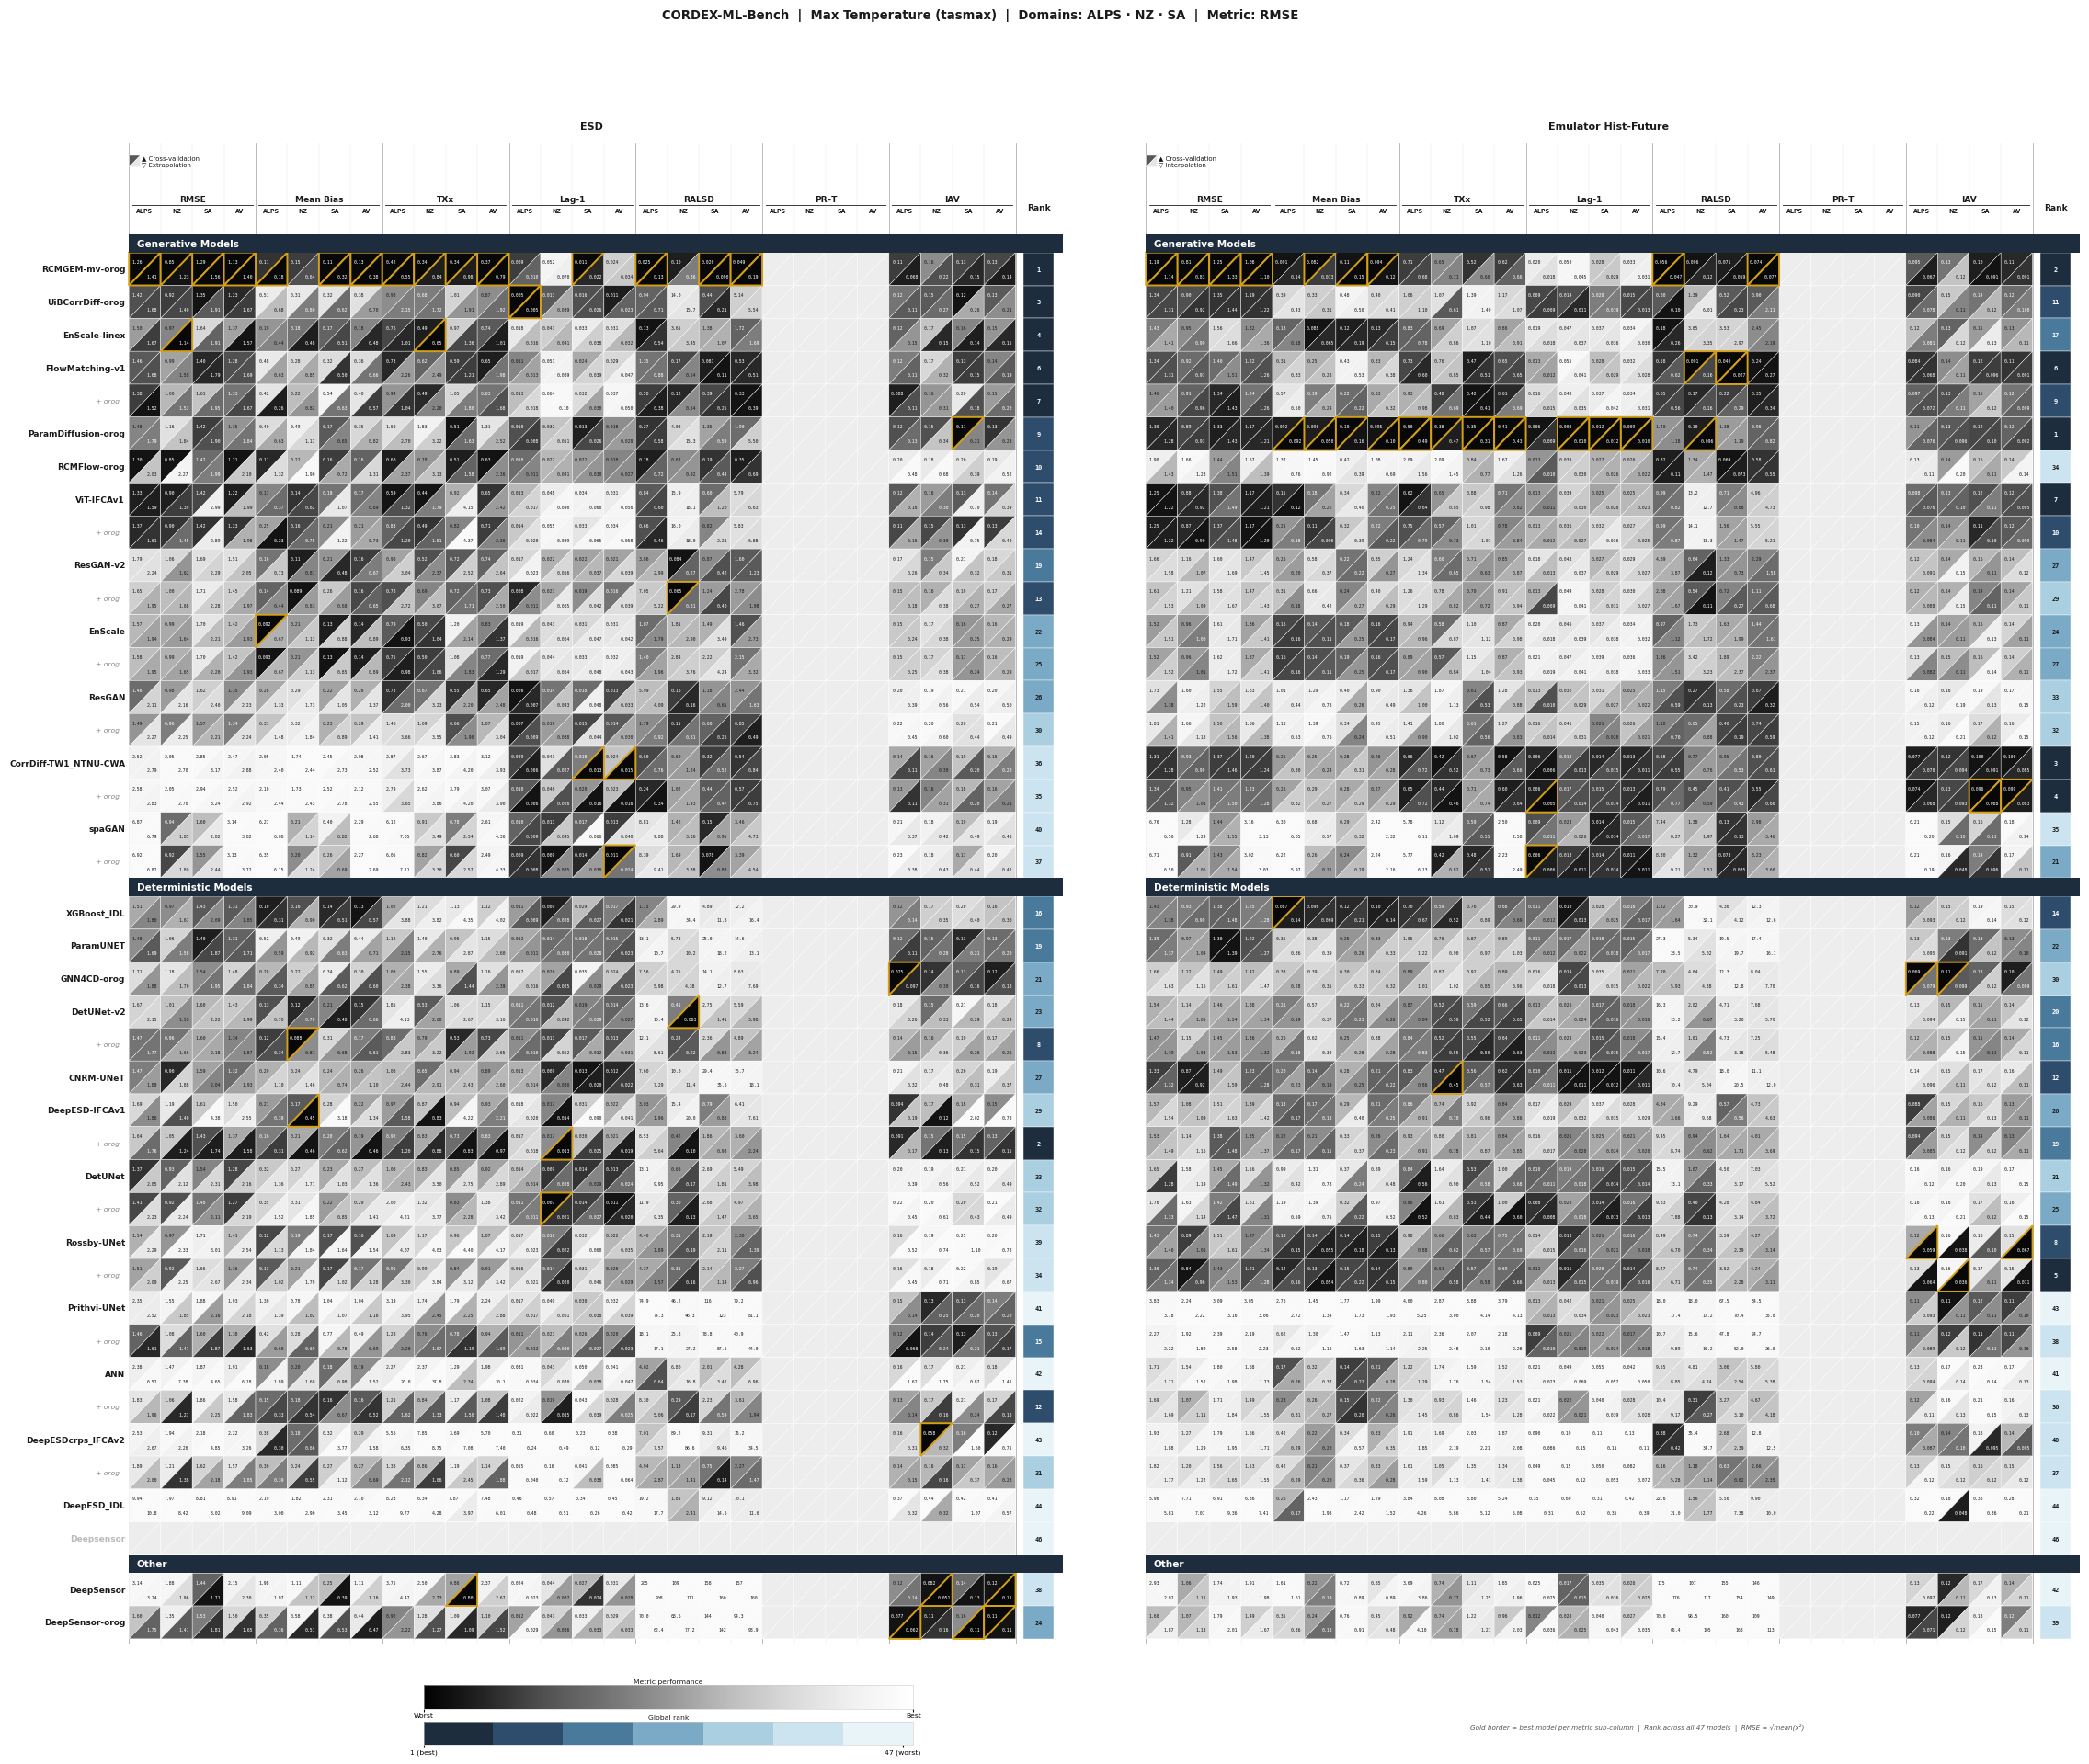

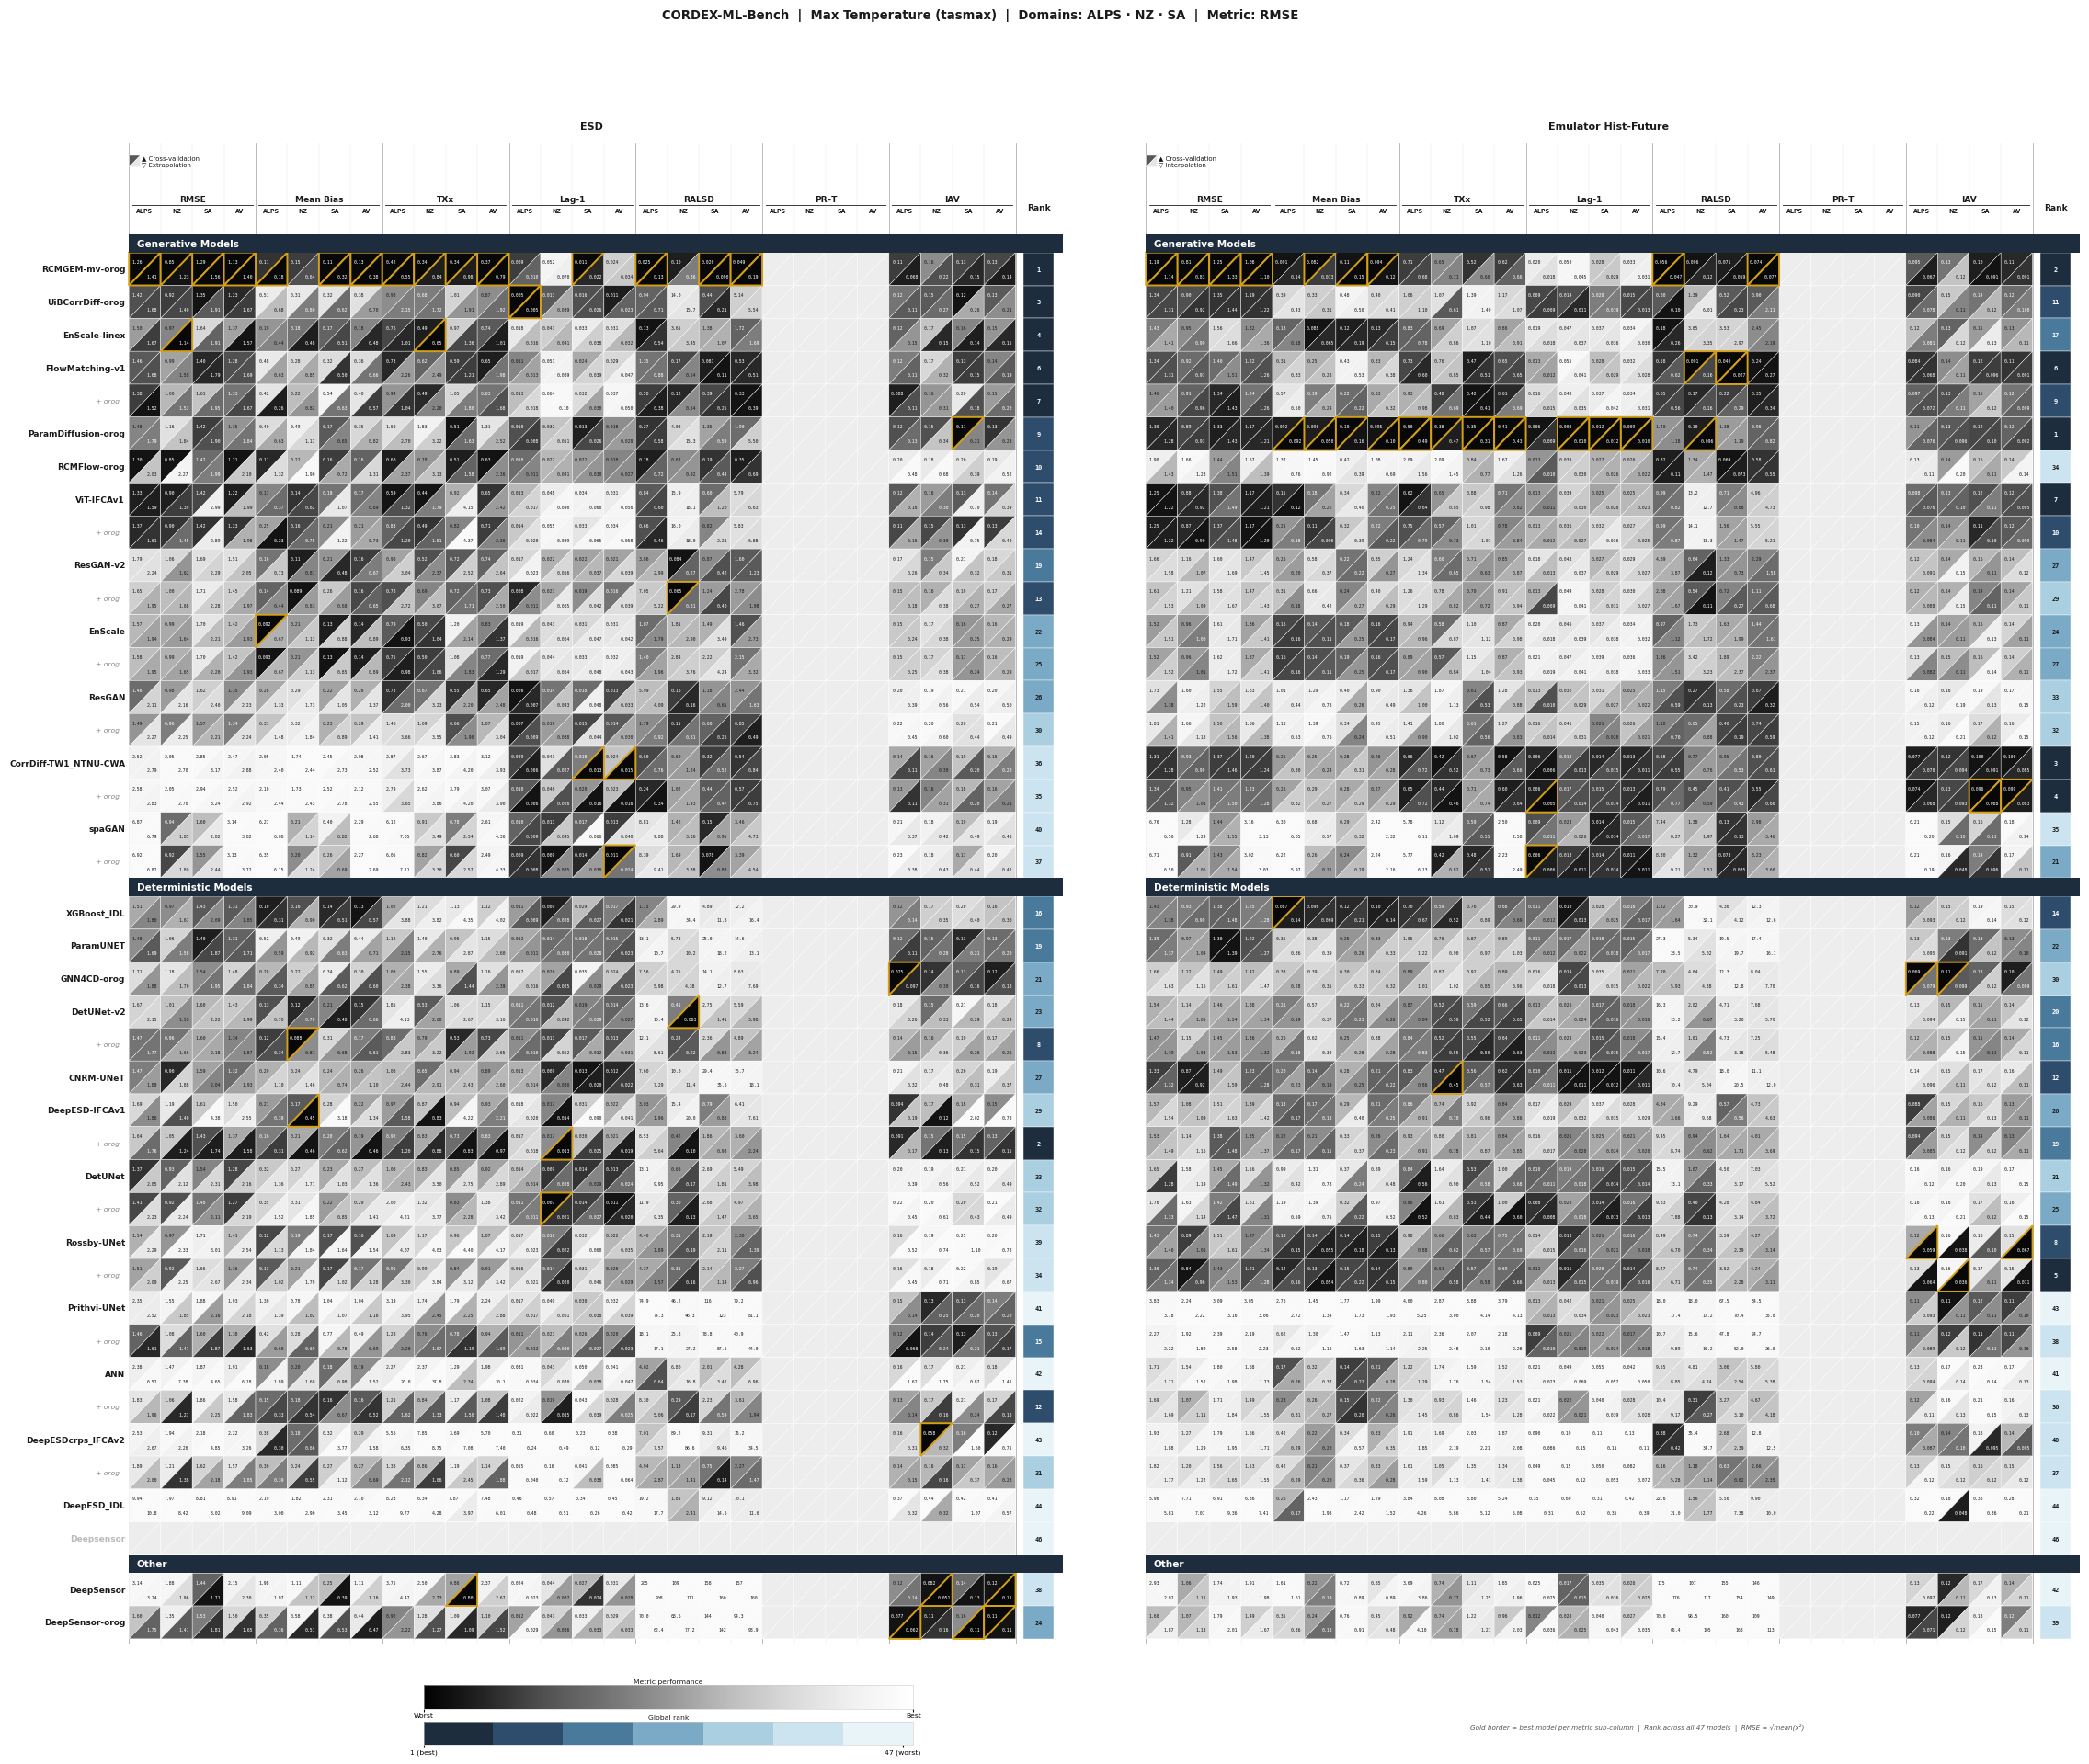

In [18]:
   plot_scorecard_full(
        variable   = "tasmax",
        diag_root  = DIAG_ROOT,
        save_path  = "/esi/project/niwa00018/rampaln/PUBLICATIONS/2026/CORDEX_ML_TF/Evaluation/figures/scorecard_tasmax_rmse_full.pdf",
    )

Loading scorecard data (average mode)…
Loading scorecard data (full mode)…
Loading scorecard data (average mode)…
Loading Rank Summary data…
  → 40 models ranked (from 40 on disk)
Saved → cordex_rank_summary.pdf


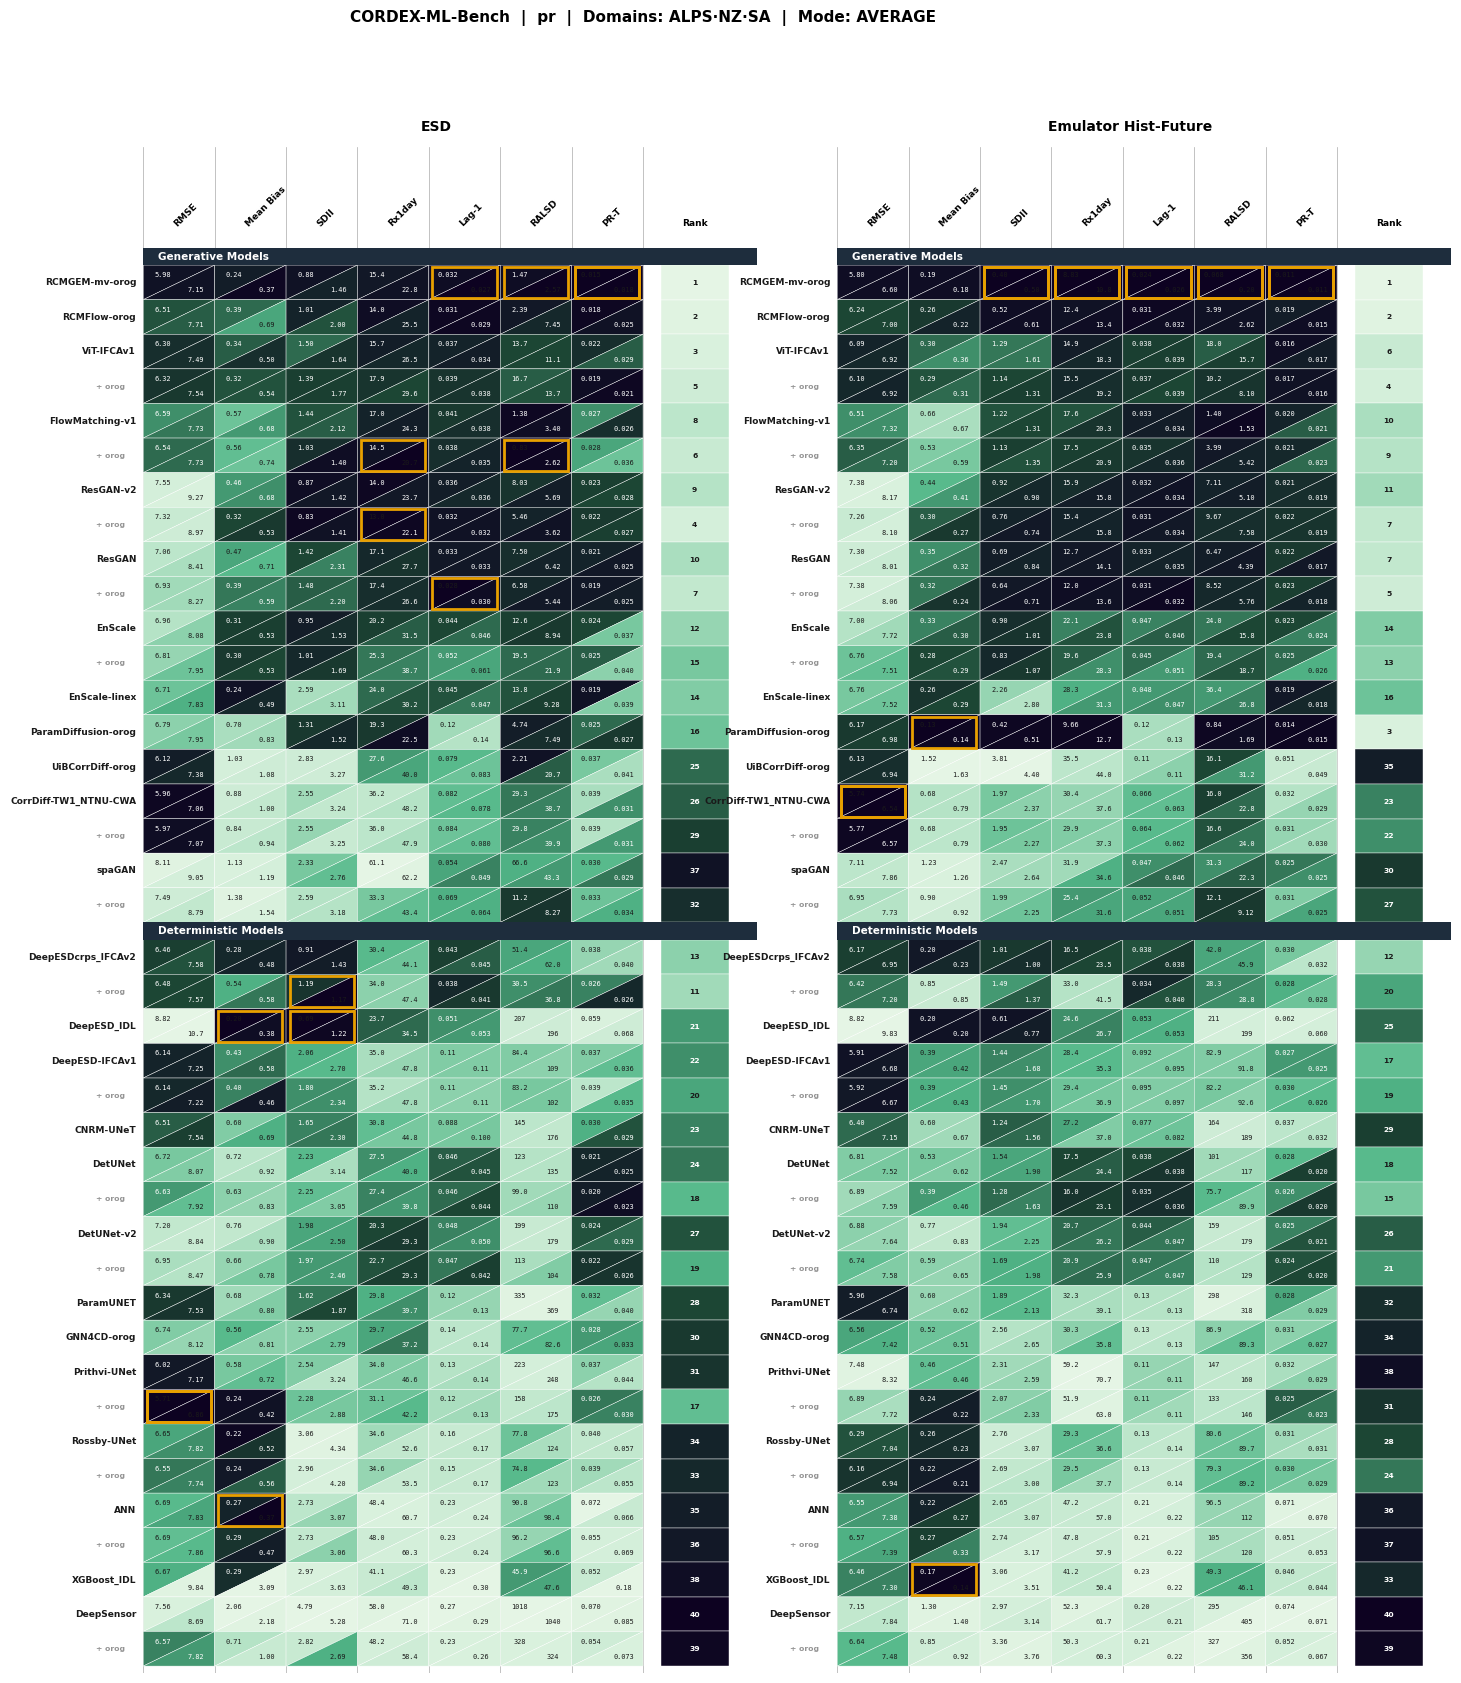

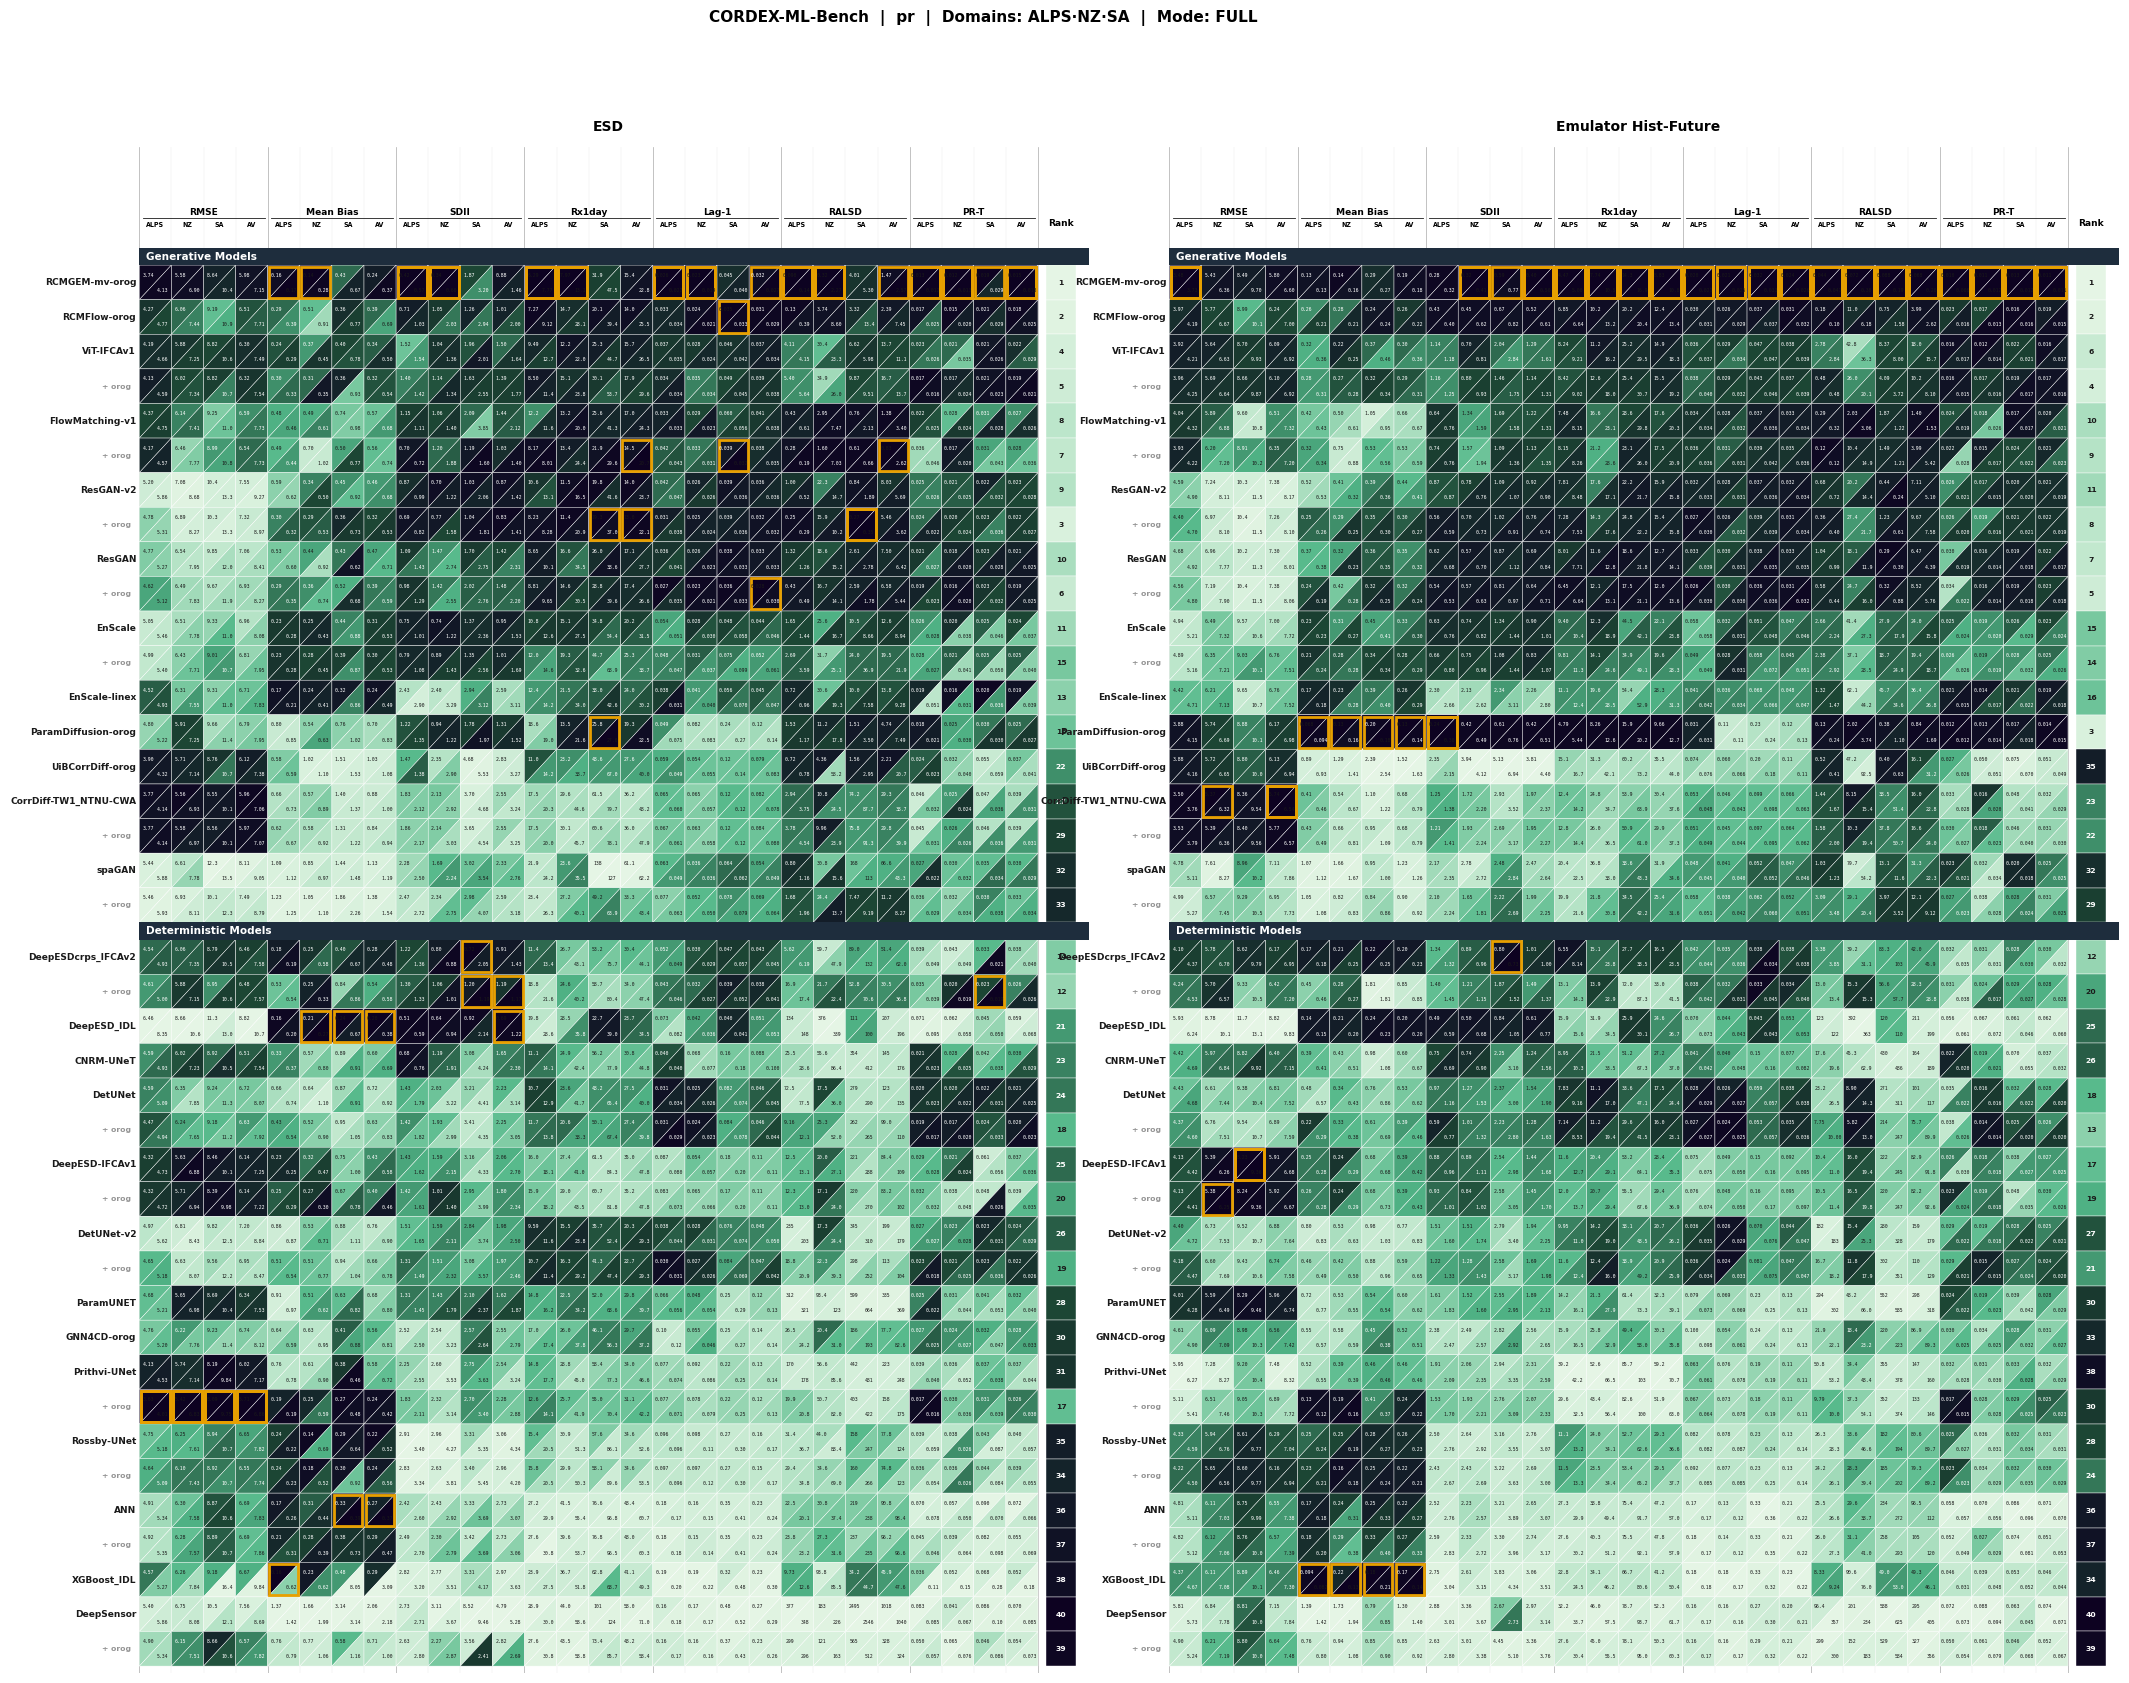

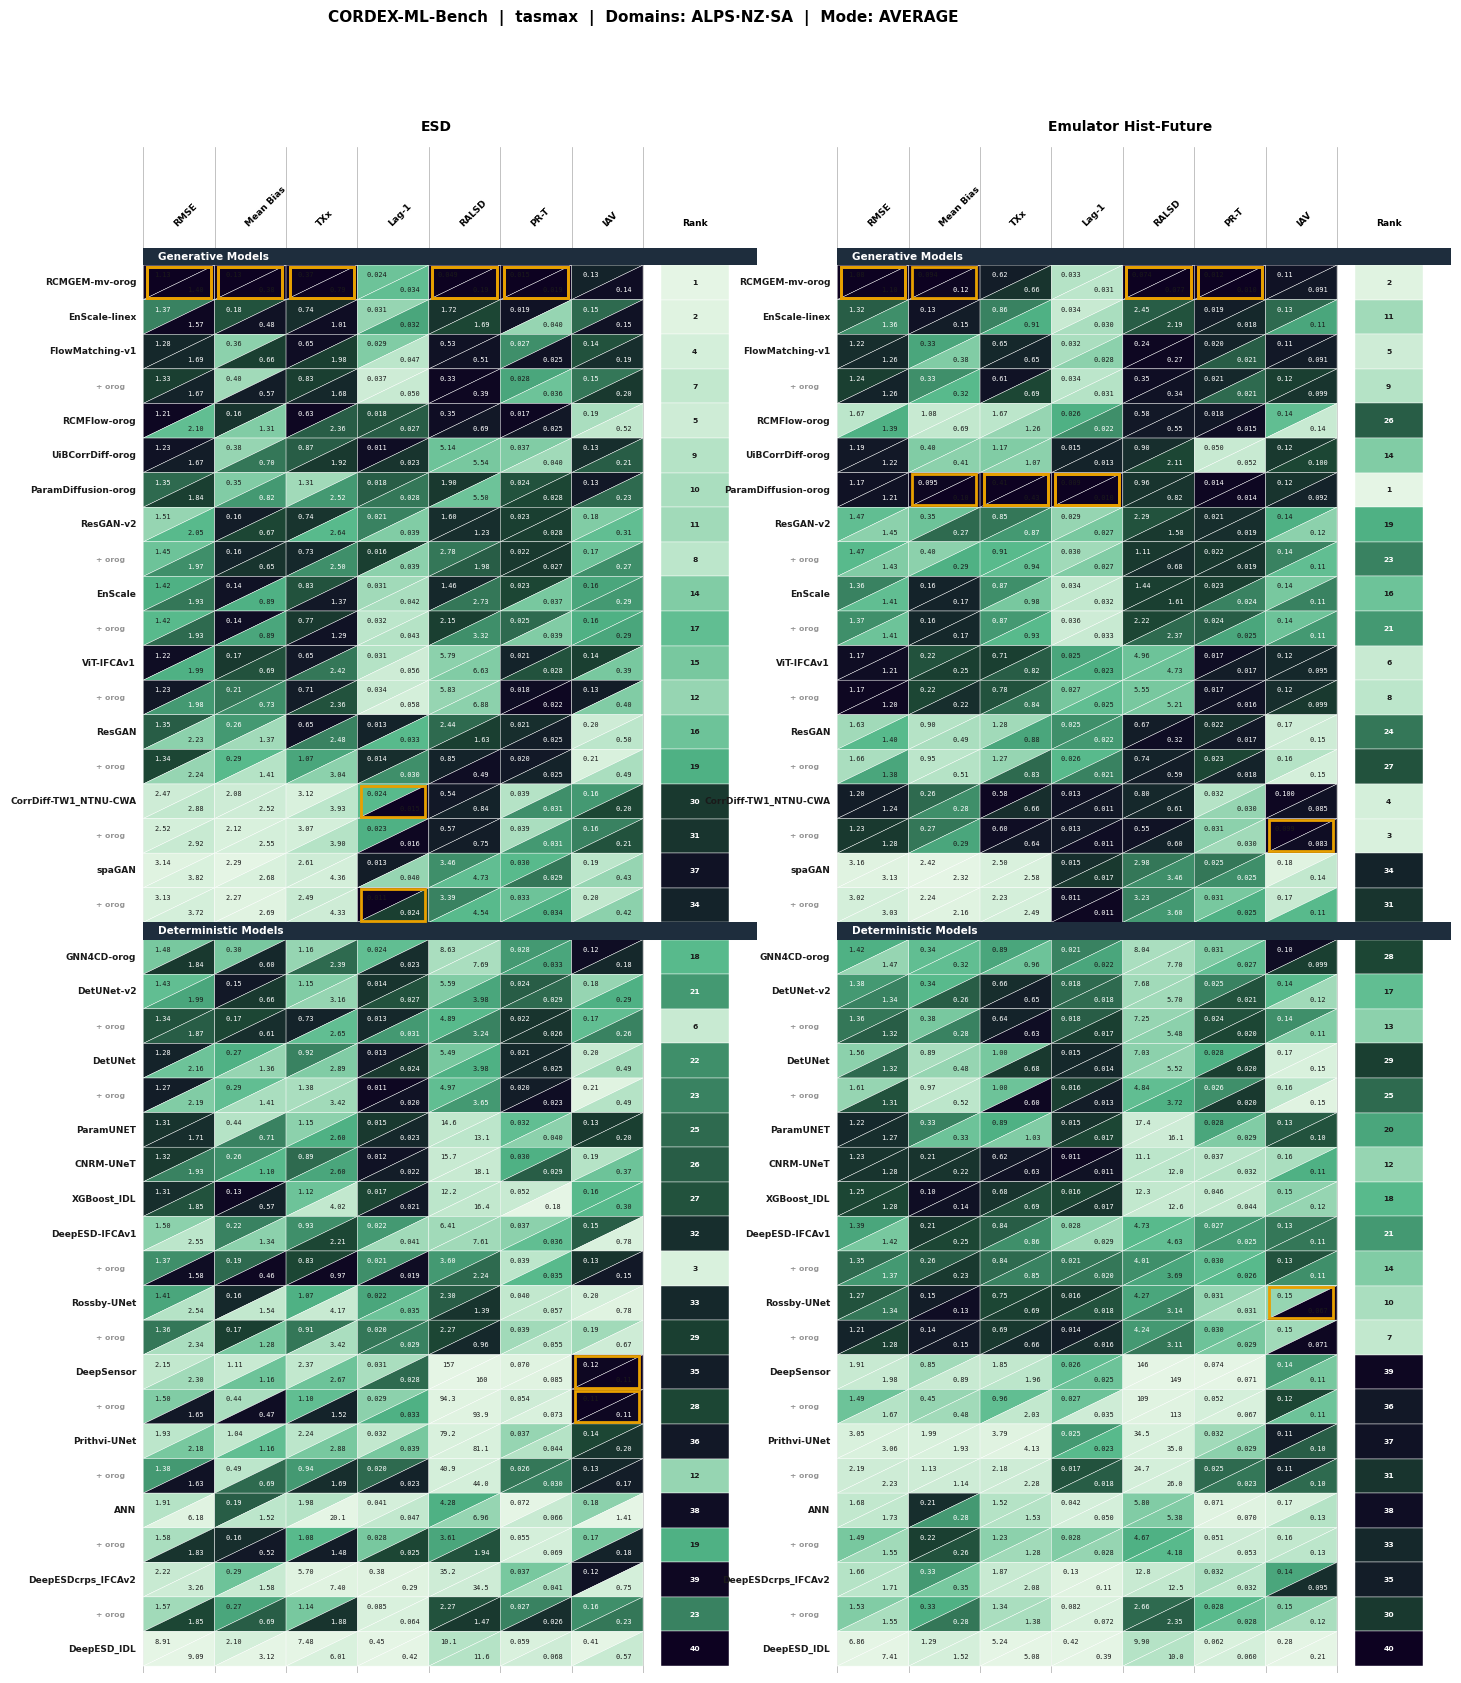

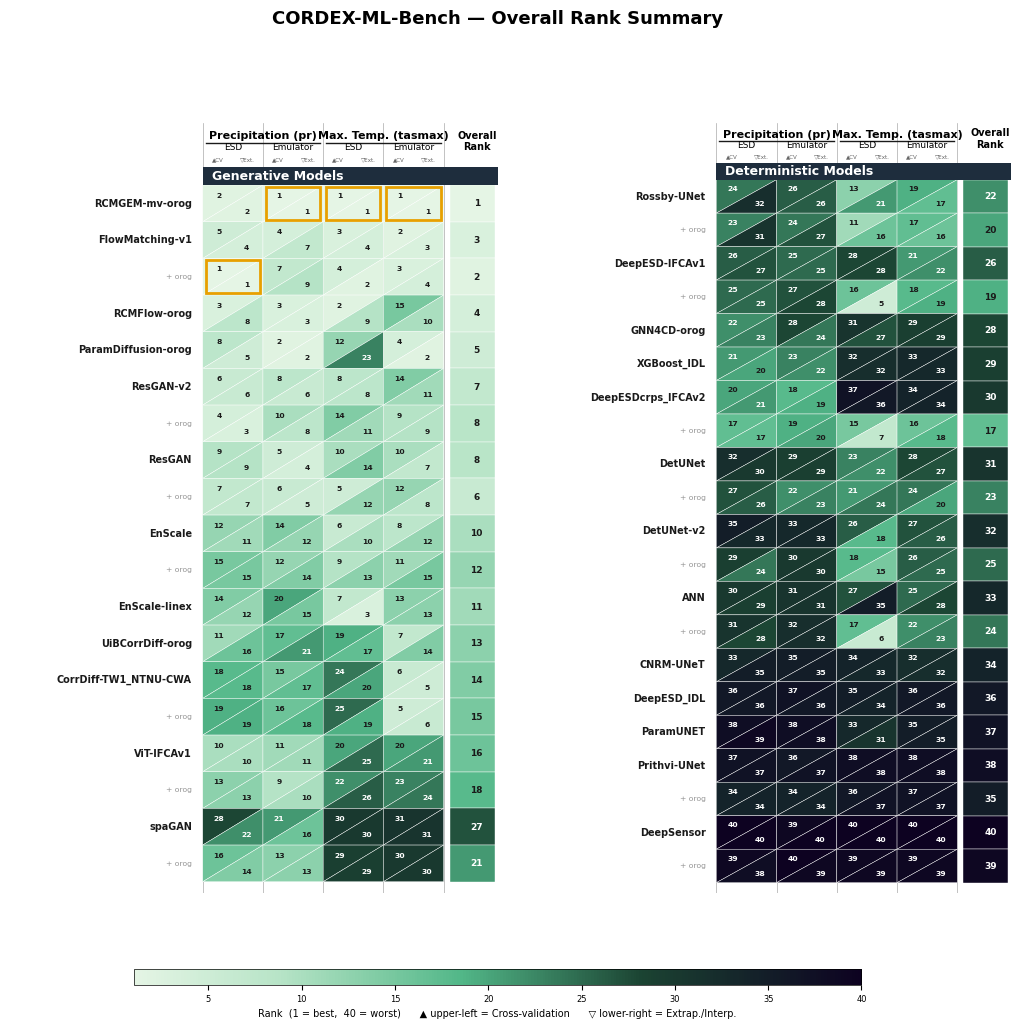

In [38]:
"""
CORDEX-ML-Bench Scorecard & Rank Summary  –  v3
================================================
Fixed:
  • Rank range: all_model_names = available only → no orog ghost inflation
  • Layout: each panel has its own independent y-axis → no dead space
  • White text: _draw_triangle guards against None/NaN before calling colormap
  • Best-model highlight: gold rectangle border around the whole cell (not triangle)
    plus forced black text for that number
  • Colormap: light-green (best) → dark-purple (worst) throughout
"""

import os
import warnings
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.path import Path
from matplotlib import rcParams

warnings.filterwarnings("ignore")

rcParams.update({
    "font.family":      "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size":        7.5,
    "axes.linewidth":   0.5,
    "pdf.fonttype":     42,
    "ps.fonttype":      42,
})

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG & COLOURS
# ─────────────────────────────────────────────────────────────────────────────

DIAG_ROOT = "./diagnostics"
DOMAINS_DEFAULT = ["ALPS_Domain", "NZ_Domain", "SA_Domain"]
OROG_SUFFIX = "-orog"
SKIP_DIRS = {".ipynb_checkpoints", "__pycache__", ".git", ".DS_Store", "tmp", "temp"}

GENERATIVE_MODELS = [
    "ResGAN", "ResGAN-v2", "FlowMatching-v1", "CorrDiff-TW1_NTNU-CWA",
    "spaGAN", "ViT-IFCAv1", "EnScale", "ParamDiffusion-orog",
    "RCMGEM-mv-orog", "RCMFlow-orog", "UiBCorrDiff-orog", "EnScale-linex",
]

DETERMINISTIC_MODELS = [
    "DetUNet", "DetUNet-v2", "Rossby-UNet", "Prithvi-UNet",
    "DeepESDcrps_IFCAv2", "DeepESD-IFCAv1", "ANN", "CNRM-UNeT",
    "DeepESD_IDL", "ParamUNET", "DeepSensor", "XGBoost_IDL", "GNN4CD-orog",
]

DISPLAY_LABELS = {}

METRICS_PR = {
    "rmse": "RMSE", "mean_bias": "Mean Bias", "sdii_bias": "SDII",
    "rx1day_bias": "Rx1day", "lag1_corr_bias": "Lag-1", "ralsd": "RALSD",
    "pr_tasmax_corr_bias": "PR-T",
}

METRICS_TASMAX = {
    "rmse": "RMSE", "mean_bias": "Mean Bias", "txx_bias": "TXx",
    "lag1_corr_bias": "Lag-1", "ralsd": "RALSD", "pr_tasmax_corr_bias": "PR-T",
    "interannual_var_bias": "IAV",
}

WHITE  = "#ffffff"
BLACK  = "#1a1a1a"
GRAY   = "#949494"
HEADER = "#1e2d3d"
GOLD   = "#e8a000"

# Slightly darkened the start color (#e5f5e5) for better visibility on white
_CORDEX_CMAP = LinearSegmentedColormap.from_list(
    "cordex_green",
    [
        (0.00, "#e5f5e5"), 
        (0.20, "#b7e4c7"),
        (0.45, "#52b788"),
        (0.70, "#1b4332"),
        (1.00, "#0d0221"),
    ],
    N=256,
)

MISSING_COLOR = (0.92, 0.92, 0.92, 1.0)

def _safe_color(cmap, v):
    if v is None or not np.isfinite(v):
        return MISSING_COLOR
    return cmap(np.clip(float(v), 0.0, 1.0))

def _rank_to_norm(rank, n_total):
    if rank is None or not np.isfinite(rank):
        return None
    return (float(rank) - 1.0) / max(n_total - 1, 1)

def _text_col(rgba, force_black=False):
    if force_black: return BLACK
    lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
    return WHITE if lum < 0.50 else BLACK

def _fmt(v):
    if not np.isfinite(v): return ""
    av = abs(v)
    if av < 0.1:  return f"{v:.3f}"
    if av < 10:   return f"{v:.2f}"
    if av < 100:  return f"{v:.1f}"
    return f"{v:.0f}"

# ─────────────────────────────────────────────────────────────────────────────
# DATA HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def _safe_rank(series):
    return series.rank(ascending=True, na_option="keep")

def compute_period_ranks(df, flat_cols, model_names):
    """Computes mean rank across metrics, then ranks those averages."""
    if df is None or df.empty:
        return {m: None for m in model_names}
    sub = {c: _safe_rank(df[c]) for c in flat_cols if c in df.columns}
    if not sub:
        return {m: None for m in model_names}
    mean_ranks = pd.DataFrame(sub).mean(axis=1)
    final_ranks = _safe_rank(mean_ranks)
    return {m: int(final_ranks[m]) if pd.notna(final_ranks.get(m, np.nan)) else None 
            for m in model_names}

def _norm_rank_matrix(mat):
    """Per-column rank normalization: 0.0 = Best (Rank 1), 1.0 = Worst."""
    out = np.full_like(mat, np.nan, dtype=float)
    for j in range(mat.shape[1]):
        col = mat[:, j]
        ranks = pd.Series(col).rank(method="average", ascending=True)
        max_r = np.nanmax(ranks.values)
        if not np.isfinite(max_r) or max_r <= 1:
            out[:, j] = np.where(np.isfinite(col), 0.0, np.nan)
        else:
            # FIX: Mapping Rank 1 -> 0.0 (Light Green)
            out[:, j] = (ranks.values - 1) / (max_r - 1)
    return out

# ─────────────────────────────────────────────────────────────────────────────
# DATA HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def discover_models(root):
    if not os.path.isdir(root): return []
    return sorted([d for d in os.listdir(root)
                   if os.path.isdir(os.path.join(root, d))
                   and d not in SKIP_DIRS and not d.startswith(".")])

def resolve_model_path(root, model, domain, experiment, variable, period):
    is_orog   = model.endswith(OROG_SUFFIX)
    base      = model[:-len(OROG_SUFFIX)] if is_orog else model
    orog      = base + OROG_SUFFIX
    base_path = os.path.join(root, base, domain, experiment, variable, period)
    orog_path = os.path.join(root, orog, domain, experiment, variable, period)
    if is_orog:
        if os.path.isdir(orog_path): return orog_path
        if os.path.isdir(base_path): return base_path
    else:
        if os.path.isdir(base_path): return base_path
        if os.path.isdir(orog_path): return orog_path
    return None

def load_scalar(path, metric):
    nc = os.path.join(path, f"metric_{metric}.nc")
    if not os.path.exists(nc): return np.nan
    try:
        ds = xr.open_dataset(nc)
        if metric in ("psd", "ralsd"):
            return float(ds.RALSD.values)
        elif metric in ("pr_tasmax_corr_bias", "PR-T"):
            return float(np.sqrt(abs(ds.correlation_bias) ** 2).mean())
        else:
            var  = list(ds.data_vars)[0]
            vals = ds[var].values.astype(float).ravel()
            fin  = vals[np.isfinite(vals)]
            return float(np.sqrt(np.mean(fin ** 2))) if fin.size > 0 else np.nan
    except Exception:
        return np.nan

def build_df(root, experiment, variable, period, domains, model_names):
    metric_dict = METRICS_PR if variable == "pr" else METRICS_TASMAX
    dom_shorts  = [d.split("_")[0] for d in domains]
    records = {}
    for model in model_names:
        row = {}
        for mkey, mlabel in metric_dict.items():
            vals = []
            for i, domain in enumerate(domains):
                path = resolve_model_path(root, model, domain, experiment, variable, period)
                v    = load_scalar(path, mkey) if path else np.nan
                row[f"{mlabel}_{dom_shorts[i]}"] = v
                if np.isfinite(v): vals.append(v)
            row[f"{mlabel}_AV"] = float(np.mean(vals)) if vals else np.nan
        records[model] = row
    return pd.DataFrame.from_dict(records, orient="index")

def _safe_rank(series):
    """Rank only entries that have values; keep NaN for missing models."""
    return series.rank(ascending=True, na_option="keep")

def compute_global_ranks(model_names, df_a, df_b, flat_cols):
    def _mean_rank(df):
        if df is None or df.empty:
            return pd.Series(np.nan, index=model_names)
        sub = {c: _safe_rank(df[c]) for c in flat_cols if c in df.columns}
        if not sub:
            return pd.Series(np.nan, index=model_names)
        return pd.DataFrame(sub).mean(axis=1)

    mr_a     = _mean_rank(df_a)
    mr_b     = _mean_rank(df_b)
    combined = (mr_a + mr_b) / 2.0 if df_b is not None else mr_a
    gr       = _safe_rank(combined)
    return {m: int(gr[m]) if pd.notna(gr.get(m, np.nan)) else None for m in model_names}

def build_panel_rows(available, global_ranks, group="generative"):
    """Build display rows for one group, sorted by global rank."""
    avail_set = set(available)
    registry  = GENERATIVE_MODELS if group == "generative" else DETERMINISTIC_MODELS

    def _rank_score(m):
        r = global_ranks.get(m) or global_ranks.get(m + OROG_SUFFIX)
        return r if r is not None else 9999

    rows = []
    for model in sorted(registry, key=_rank_score):
        already_orog = model.endswith(OROG_SUFFIX)
        orog_name    = model + OROG_SUFFIX
        rows.append(dict(kind="model",
                         label=DISPLAY_LABELS.get(model, model),
                         model_name=model, is_orog=False,
                         has_data=(model in avail_set)))
        if not already_orog and orog_name in avail_set:
            rows.append(dict(kind="model", label="+ orog",
                             model_name=orog_name, is_orog=True, has_data=True))
    return rows

def _compute_y_positions(rows):
    """
    Assign y positions top-to-bottom for a list of model rows.
    Returns (y_map, total_height) where total_height EXCLUDES the section header
    (header is drawn above y=total_h).
    """
    MODEL_H = 1.00
    n_models = sum(1 for r in rows if r["kind"] == "model")
    total_h  = n_models * MODEL_H
    y_map = {}
    y_cur = total_h
    for r in rows:
        if r["kind"] == "model":
            y_cur -= MODEL_H
            y_map[r["model_name"]] = y_cur
    return y_map, total_h

# ─────────────────────────────────────────────────────────────────────────────
# DRAWING PRIMITIVES
# ─────────────────────────────────────────────────────────────────────────────

SECTION_H = 0.50
MODEL_H   = 1.00

def _draw_triangle(ax, x, y, norm_val, upper):
    """
    Draw one half-cell triangle.
    norm_val in [0,1] (0=worst colour, 1=best colour) or None for missing.
    Guards None/NaN BEFORE calling the colormap (fixes white-text-on-white bug).
    Returns the RGBA face colour used.
    """
    color = _safe_color(_CORDEX_CMAP, norm_val)   # None → MISSING_COLOR (safe)
    codes = [Path.MOVETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY]
    if upper:
        verts = [(x, y + MODEL_H), (x + 1, y + MODEL_H), (x, y), (x, y + MODEL_H)]
    else:
        verts = [(x + 1, y), (x + 1, y + MODEL_H), (x, y), (x + 1, y)]
    ax.add_patch(mpatches.PathPatch(
        Path(verts, codes),
        facecolor=color, edgecolor=WHITE, linewidth=0.3, zorder=2,
    ))
    return color

def _draw_best_border(ax, x, y):
    """
    Clean gold rectangle outline around the whole 1×1 cell.
    Avoids the ugly diagonal slash that comes from outlining a triangle.
    """
    rect = plt.Rectangle(
        (x + 0.05, y + 0.05), 0.90, MODEL_H - 0.10,
        facecolor="none", edgecolor=GOLD,
        linewidth=2.0, zorder=6,
    )
    ax.add_patch(rect)

def _norm_rank_matrix(mat):
    """Per-column rank → normalised [0=worst … 1=best]."""
    out = np.full_like(mat, np.nan, dtype=float)
    for j in range(mat.shape[1]):
        col   = mat[:, j]
        ranks = pd.Series(col).rank(method="average", ascending=True)
        max_r = np.nanmax(ranks.values)
        if not np.isfinite(max_r) or max_r <= 1:
            out[:, j] = np.where(np.isfinite(col), 0.5, np.nan)
        else:
            out[:, j] = 1.0 - (ranks.values - 1) / (max_r - 1)
    return out

# ─────────────────────────────────────────────────────────────────────────────
# 1. SCORECARD PLOT
# ─────────────────────────────────────────────────────────────────────────────

import matplotlib as mpl
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def plot_scorecard(
    variable="pr",
    diag_root=DIAG_ROOT,
    domains=None,
    region_mode="average",
    esd_experiment="ESD_pseudo_reality",
    esd_period_a="Perfect_cross_validation",
    esd_period_b="Perfect_extrapolation",
    emu_experiment="Emulator_hist_future",
    emu_period_a="Perfect_cross_validation",
    emu_period_b="Perfect_interpolation",
    save_path=None,
    figsize=None,
):
    """Generates a scorecard plot comparing ESD and Emulator performance.

    Note: This function contains references to undefined variables
    (`ranks_a`, `ranks_b`, `n_total_ranked`) in the provided snippet, which
    have been flagged with FIXME comments.
    """
    if domains is None:
        domains = DOMAINS_DEFAULT

    available = discover_models(diag_root)
    all_model_names = (
        available if available else GENERATIVE_MODELS + DETERMINISTIC_MODELS
    )

    metric_dict = METRICS_PR if variable == "pr" else METRICS_TASMAX
    base_metrics = list(metric_dict.values())
    dom_shorts = [d.split("_")[0] for d in domains]
    sub_cols = (dom_shorts + ["AV"]) if region_mode == "full" else ["AV"]
    flat_cols = [f"{m}_{s}" for m in base_metrics for s in sub_cols]

    print(f"Loading scorecard data ({region_mode} mode)…")
    df_esd_a = build_df(
        diag_root, esd_experiment, variable, esd_period_a, domains, all_model_names
    )
    df_esd_b = build_df(
        diag_root, esd_experiment, variable, esd_period_b, domains, all_model_names
    )
    df_emu_a = build_df(
        diag_root, emu_experiment, variable, emu_period_a, domains, all_model_names
    )
    df_emu_b = build_df(
        diag_root, emu_experiment, variable, emu_period_b, domains, all_model_names
    )

    global_ranks_esd = compute_global_ranks(
        all_model_names, df_esd_a, df_esd_b, flat_cols
    )
    global_ranks_emu = compute_global_ranks(
        all_model_names, df_emu_a, df_emu_b, flat_cols
    )
    n_global = len([v for v in global_ranks_esd.values() if v is not None])

    gen_rows = build_panel_rows(available, global_ranks_esd, "generative")
    det_rows = build_panel_rows(available, global_ranks_esd, "deterministic")
    all_rows = (
        [dict(kind="section", label="Generative Models", model_name=None)]
        + gen_rows
        + [dict(kind="section", label="Deterministic Models", model_name=None)]
        + det_rows
    )

    total_h = sum(
        SECTION_H if r["kind"] == "section" else MODEL_H for r in all_rows
    )
    y_cur, y_map = total_h, {}
    for r in all_rows:
        h = SECTION_H if r["kind"] == "section" else MODEL_H
        y_cur -= h
        if r["kind"] == "model":
            y_map[r["model_name"]] = y_cur

    n_c = len(flat_cols)
    n_sub = len(sub_cols)
    cell = 0.30 if region_mode == "full" else 0.72
    lbl_w, gap_w = 3.0, 0.8
    panel_w = n_c * cell + 1.1
    tot_w = lbl_w + panel_w * 2 + gap_w + 0.2
    tot_h = total_h * 0.38 + 2.8

    fig = plt.figure(figsize=figsize or (tot_w, tot_h), facecolor=WHITE)
    lf, pf = lbl_w / tot_w, panel_w / tot_w
    gf = gap_w / tot_w
    bot, top = 0.07, 0.90
    ax_esd = fig.add_axes([lf, bot, pf, top - bot])
    ax_emu = fig.add_axes([lf + pf + gf, bot, pf, top - bot])

    def _render_sc_panel(ax, df_a, df_b, title, g_ranks):
        model_rows = [r for r in all_rows if r["kind"] == "model"]
        va = np.array(
            [
                [
                    (
                        df_a.loc[r["model_name"], c]
                        if r["model_name"] in df_a.index and c in df_a.columns
                        else np.nan
                    )
                    for c in flat_cols
                ]
                for r in model_rows
            ]
        )
        vb = np.array(
            [
                [
                    (
                        df_b.loc[r["model_name"], c]
                        if r["model_name"] in df_b.index and c in df_b.columns
                        else np.nan
                    )
                    for c in flat_cols
                ]
                for r in model_rows
            ]
        )

        na, nb = _norm_rank_matrix(va), _norm_rank_matrix(vb)

        best_a = [
            (
                int(np.nanargmax(na[:, j]))
                if np.any(np.isfinite(na[:, j]))
                else -1
            )
            for j in range(n_c)
        ]
        best_b = [
            (
                int(np.nanargmax(nb[:, j]))
                if np.any(np.isfinite(nb[:, j]))
                else -1
            )
            for j in range(n_c)
        ]

        # Section headers
        for idx, r in enumerate(all_rows):
            if r["kind"] != "section":
                continue
            y_tops = [
                y_map[rr["model_name"]] + MODEL_H
                for rr in all_rows[idx + 1 :]
                if rr["kind"] == "model" and rr["model_name"] in y_map
            ]
            if not y_tops:
                continue

            ax.add_patch(
                plt.Rectangle(
                    [0, max(y_tops)],
                    n_c + 1.6,
                    SECTION_H,
                    facecolor=HEADER,
                    edgecolor="none",
                    clip_on=False,
                    zorder=4,
                )
            )
            ax.text(
                0.2,
                max(y_tops) + SECTION_H * 0.5,
                r["label"],
                ha="left",
                va="center",
                fontsize=7.5,
                color=WHITE,
                fontweight="bold",
                zorder=5,
                clip_on=False,
            )

        for i, r in enumerate(model_rows):
            if r["model_name"] not in y_map:
                continue
            y = y_map[r["model_name"]]
            ax.text(
                -0.25 if r["is_orog"] else -0.10,
                y + 0.5,
                r["label"],
                ha="right",
                va="center",
                fontsize=5.5 if r["is_orog"] else 6.5,
                color=GRAY if r["is_orog"] else BLACK,
                fontweight="semibold",
            )

            for j in range(n_c):
                has_data = r.get("has_data", True)
                is_ba = (best_a[j] == i) and has_data
                is_bb = (best_b[j] == i) and has_data

                ca = _draw_triangle(
                    ax, j, y, na[i, j] if has_data else None, upper=True
                )
                cb = _draw_triangle(
                    ax, j, y, nb[i, j] if has_data else None, upper=False
                )

                if is_ba:
                    _draw_best_border(ax, j, y)
                if is_bb:
                    _draw_best_border(ax, j, y)

                fs = 3.5 if region_mode == "full" else 5.0
                if has_data and np.isfinite(va[i, j]):
                    ax.text(
                        j + 0.27,
                        y + 0.72,
                        _fmt(va[i, j]),
                        ha="center",
                        va="center",
                        fontsize=fs,
                        color=_text_col(ca, is_ba),
                        fontfamily="monospace",
                        zorder=7,
                    )
                if has_data and np.isfinite(vb[i, j]):
                    ax.text(
                        j + 0.73,
                        y + 0.28,
                        _fmt(vb[i, j]),
                        ha="center",
                        va="center",
                        fontsize=fs,
                        color=_text_col(cb, is_bb),
                        fontfamily="monospace",
                        zorder=7,
                    )

            rk = g_ranks.get(r["model_name"])

            # FIXME: ranks_a, ranks_b, and n_total_ranked are undefined in this scope
            try:
                rk_a, rk_b = (
                    ranks_a.get(r["model_name"]),
                    ranks_b.get(r["model_name"]),
                )
                nrm_a = _rank_to_norm(rk_a, n_total_ranked)
                nrm_b = _rank_to_norm(rk_b, n_total_ranked)

                cra = _draw_triangle(
                    ax, len(flat_cols) + 0.25, y, nrm_a, upper=True
                )
                crb = _draw_triangle(
                    ax, len(flat_cols) + 0.25, y, nrm_b, upper=False
                )

                if rk_a:
                    ax.text(
                        len(flat_cols) + 0.52,
                        y + 0.72,
                        str(rk_a),
                        ha="center",
                        va="center",
                        fontsize=5,
                        color=_text_col(cra),
                        fontweight="bold",
                    )
                if rk_b:
                    ax.text(
                        len(flat_cols) + 0.98,
                        y + 0.28,
                        str(rk_b),
                        ha="center",
                        va="center",
                        fontsize=5,
                        color=_text_col(crb),
                        fontweight="bold",
                    )
            except NameError:
                pass

            nrm = _rank_to_norm(rk, n_global)
            rc = _safe_color(_CORDEX_CMAP, nrm)
            ax.add_patch(
                plt.Rectangle(
                    [n_c + 0.25, y],
                    0.95,
                    MODEL_H,
                    facecolor=rc,
                    edgecolor=WHITE,
                    linewidth=0.3,
                )
            )
            if rk is not None:
                ax.text(
                    n_c + 0.725,
                    y + 0.5,
                    str(rk),
                    ha="center",
                    va="center",
                    fontsize=5.5,
                    color=_text_col(rc),
                    fontweight="bold",
                )

        for j, metric in enumerate(base_metrics):
            if region_mode == "full":
                sx = j * n_sub
                ax.text(
                    sx + (n_sub - 1) / 2.0 + 0.5,
                    total_h + SECTION_H + 0.40,
                    metric,
                    ha="center",
                    va="bottom",
                    fontsize=6.5,
                    fontweight="bold",
                )
                ax.plot(
                    [sx + 0.1, sx + n_sub - 0.1],
                    [total_h + SECTION_H + 0.35] * 2,
                    color=BLACK,
                    lw=0.6,
                    clip_on=False,
                )
                for k, sub in enumerate(sub_cols):
                    ax.text(
                        sx + k + 0.5,
                        total_h + SECTION_H + 0.08,
                        sub,
                        ha="center",
                        va="bottom",
                        fontsize=4.5,
                        fontweight="semibold",
                    )
            else:
                ax.text(
                    j + 0.5,
                    total_h + SECTION_H + 0.08,
                    metric,
                    ha="left",
                    va="bottom",
                    fontsize=6.5,
                    fontweight="bold",
                    rotation=45,
                    rotation_mode="anchor",
                )

        ax.text(
            n_c + 0.725,
            total_h + SECTION_H + 0.08,
            "Rank",
            ha="center",
            va="bottom",
            fontsize=6.5,
            fontweight="bold",
        )
        ax.set_title(title, fontsize=10, fontweight="bold", pad=12)

        for j in range(n_c + 1):
            is_maj = (region_mode == "average") or (j % n_sub == 0)
            ax.axvline(
                j,
                color="#aaaaaa" if is_maj else "#e0e0e0",
                linewidth=0.5 if is_maj else 0.2,
                zorder=1,
            )

        ax.set_xlim(-0.2, n_c + 1.4)
        ax.set_ylim(-0.2, total_h + SECTION_H + 2.4)
        ax.axis("off")
        ax.set_facecolor(WHITE)

    _render_sc_panel(ax_esd, df_esd_a, df_esd_b, "ESD", global_ranks_esd)
    _render_sc_panel(
        ax_emu, df_emu_a, df_emu_b, "Emulator Hist-Future", global_ranks_emu
    )

    dom_str = "·".join(d.split("_")[0] for d in domains)
    fig.suptitle(
        f"CORDEX-ML-Bench  |  {variable}  |  Domains: {dom_str}  |  Mode: {region_mode.upper()}",
        fontsize=11,
        fontweight="bold",
        y=0.975,
    )

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
    else:
        plt.show()
    return fig


def plot_rank_summary(
    diag_root=DIAG_ROOT,
    domains=None,
    save_path=None,
    figsize=(13.0, 10.0),
):
    """Generates a two-column layout showing the rank summary."""
    if domains is None:
        domains = DOMAINS_DEFAULT

    available = discover_models(diag_root)
    all_model_names = (
        available if available else GENERATIVE_MODELS + DETERMINISTIC_MODELS
    )

    def _avg_df(var, exp, period):
        metric_dict = METRICS_PR if var == "pr" else METRICS_TASMAX
        cols = [f"{m}_AV" for m in metric_dict.values()]
        df = build_df(diag_root, exp, var, period, domains, all_model_names)
        return df, cols

    print("Loading Rank Summary data…")
    df_pr_esd_a, c_pr = _avg_df(
        "pr", "ESD_pseudo_reality", "Perfect_cross_validation"
    )
    df_pr_esd_b, _ = _avg_df(
        "pr", "ESD_pseudo_reality", "Perfect_extrapolation"
    )
    df_pr_emu_a, _ = _avg_df(
        "pr", "Emulator_hist_future", "Perfect_cross_validation"
    )
    df_pr_emu_b, _ = _avg_df(
        "pr", "Emulator_hist_future", "Perfect_interpolation"
    )

    df_tx_esd_a, c_tx = _avg_df(
        "tasmax", "ESD_pseudo_reality", "Perfect_cross_validation"
    )
    df_tx_esd_b, _ = _avg_df(
        "tasmax", "ESD_pseudo_reality", "Perfect_extrapolation"
    )
    df_tx_emu_a, _ = _avg_df(
        "tasmax", "Emulator_hist_future", "Perfect_cross_validation"
    )
    df_tx_emu_b, _ = _avg_df(
        "tasmax", "Emulator_hist_future", "Perfect_interpolation"
    )

    def _rank_col(df, cols):
        if df is None or df.empty:
            return pd.Series(np.nan, index=all_model_names)
        avail = [c for c in cols if c in df.columns]
        if not avail:
            return pd.Series(np.nan, index=all_model_names)
        return _safe_rank(df[avail].mean(axis=1))

    r_pr_esd_cv = _rank_col(df_pr_esd_a, c_pr)
    r_pr_esd_ex = _rank_col(df_pr_esd_b, c_pr)
    r_pr_emu_cv = _rank_col(df_pr_emu_a, c_pr)
    r_pr_emu_ip = _rank_col(df_pr_emu_b, c_pr)

    r_tx_esd_cv = _rank_col(df_tx_esd_a, c_tx)
    r_tx_esd_ex = _rank_col(df_tx_esd_b, c_tx)
    r_tx_emu_cv = _rank_col(df_tx_emu_a, c_tx)
    r_tx_emu_ip = _rank_col(df_tx_emu_b, c_tx)

    df_stk = pd.DataFrame(
        {
            0: r_pr_esd_cv,
            1: r_pr_esd_ex,
            2: r_pr_emu_cv,
            3: r_pr_emu_ip,
            4: r_tx_esd_cv,
            5: r_tx_esd_ex,
            6: r_tx_emu_cv,
            7: r_tx_emu_ip,
        }
    )

    global_rank_s = _safe_rank(df_stk.mean(axis=1))
    global_ranks = {m: r for m, r in global_rank_s.items() if pd.notna(r)}
    n_global = len(global_ranks)
    print(f"  → {n_global} models ranked (from {len(all_model_names)} on disk)")

    def _best_of(rs):
        m = rs.idxmin() if rs.notna().any() else None
        return m if (m is not None and pd.notna(rs.get(m, np.nan))) else None

    best_upper = [
        _best_of(r_pr_esd_cv),
        _best_of(r_pr_emu_cv),
        _best_of(r_tx_esd_cv),
        _best_of(r_tx_emu_cv),
    ]
    best_lower = [
        _best_of(r_pr_esd_ex),
        _best_of(r_pr_emu_ip),
        _best_of(r_tx_esd_ex),
        _best_of(r_tx_emu_ip),
    ]

    gen_rows = build_panel_rows(available, global_ranks, "generative")
    det_rows = build_panel_rows(available, global_ranks, "deterministic")

    y_gen, h_gen = _compute_y_positions(gen_rows)
    y_det, h_det = _compute_y_positions(det_rows)

    LBL_W = 3.2
    N_COLS = 4
    OVR_W = 0.85

    fig, (ax_g, ax_d) = plt.subplots(
        1,
        2,
        figsize=figsize,
        facecolor=WHITE,
        gridspec_kw={"wspace": 0.04},
    )

    def _render_rank_panel(ax, rows, y_map, total_h, panel_label):
        ax.set_facecolor(WHITE)

        y_tops = [
            y_map[r["model_name"]] + MODEL_H
            for r in rows
            if r["kind"] == "model" and r["model_name"] in y_map
        ]
        if y_tops:
            bar_y = max(y_tops)
            ax.add_patch(
                plt.Rectangle(
                    [0, bar_y],
                    N_COLS + OVR_W + 0.05,
                    SECTION_H,
                    facecolor=HEADER,
                    edgecolor="none",
                    clip_on=False,
                    zorder=4,
                )
            )
            ax.text(
                0.15,
                bar_y + SECTION_H * 0.5,
                panel_label,
                ha="left",
                va="center",
                fontsize=9,
                color=WHITE,
                fontweight="bold",
                zorder=5,
                clip_on=False,
            )

        model_rows = [
            r
            for r in rows
            if r["kind"] == "model" and r["model_name"] in y_map
        ]

        for r in model_rows:
            m = r["model_name"]
            y = y_map[m]

            ax.text(
                -0.18,
                y + 0.5,
                r["label"],
                ha="right",
                va="center",
                fontsize=5.5 if r["is_orog"] else 7.0,
                color=GRAY if r["is_orog"] else BLACK,
                fontweight="normal" if r["is_orog"] else "semibold",
                zorder=7,
            )

            col_data = [
                (r_pr_esd_cv.get(m), r_pr_esd_ex.get(m)),
                (r_pr_emu_cv.get(m), r_pr_emu_ip.get(m)),
                (r_tx_esd_cv.get(m), r_tx_esd_ex.get(m)),
                (r_tx_emu_cv.get(m), r_tx_emu_ip.get(m)),
            ]

            for x, (rk_u, rk_l) in enumerate(col_data):
                n_u = _rank_to_norm(rk_u, n_global) if pd.notna(rk_u) else None
                n_l = _rank_to_norm(rk_l, n_global) if pd.notna(rk_l) else None
                is_bu = m == best_upper[x]
                is_bl = m == best_lower[x]

                ca = _draw_triangle(ax, x, y, n_u, upper=True)
                cb = _draw_triangle(ax, x, y, n_l, upper=False)

                if is_bu or is_bl:
                    _draw_best_border(ax, x, y)

                if pd.notna(rk_u):
                    ax.text(
                        x + 0.27,
                        y + 0.72,
                        f"{int(rk_u)}",
                        ha="center",
                        va="center",
                        fontsize=5.5,
                        color=_text_col(ca, is_bu),
                        fontweight="bold",
                        zorder=8,
                    )
                if pd.notna(rk_l):
                    ax.text(
                        x + 0.73,
                        y + 0.28,
                        f"{int(rk_l)}",
                        ha="center",
                        va="center",
                        fontsize=5.5,
                        color=_text_col(cb, is_bl),
                        fontweight="bold",
                        zorder=8,
                    )

            rk = global_ranks.get(m)
            nrm = _rank_to_norm(rk, n_global)
            rc = _safe_color(_CORDEX_CMAP, nrm)
            ax.add_patch(
                plt.Rectangle(
                    [N_COLS + 0.10, y],
                    OVR_W - 0.10,
                    MODEL_H,
                    facecolor=rc,
                    edgecolor=WHITE,
                    linewidth=0.3,
                )
            )
            if rk is not None:
                ax.text(
                    N_COLS + 0.55,
                    y + 0.5,
                    str(int(rk)),
                    ha="center",
                    va="center",
                    fontsize=6.5,
                    color=_text_col(rc),
                    fontweight="bold",
                    zorder=7,
                )

        hdr_y = total_h + SECTION_H
        ax.text(
            1.0,
            hdr_y + 0.70,
            "Precipitation (pr)",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
        )
        ax.plot(
            [0.05, 1.95], [hdr_y + 0.64] * 2, color=BLACK, lw=1.0, clip_on=False
        )
        ax.text(
            0.5, hdr_y + 0.40, "ESD", ha="center", va="bottom", fontsize=6.5
        )
        ax.text(
            1.5,
            hdr_y + 0.40,
            "Emulator",
            ha="center",
            va="bottom",
            fontsize=6.5,
        )

        ax.text(
            3.0,
            hdr_y + 0.70,
            "Max. Temp. (tasmax)",
            ha="center",
            va="bottom",
            fontsize=8,
            fontweight="bold",
        )
        ax.plot(
            [2.05, 3.95], [hdr_y + 0.64] * 2, color=BLACK, lw=1.0, clip_on=False
        )
        ax.text(
            2.5, hdr_y + 0.40, "ESD", ha="center", va="bottom", fontsize=6.5
        )
        ax.text(
            3.5,
            hdr_y + 0.40,
            "Emulator",
            ha="center",
            va="bottom",
            fontsize=6.5,
        )

        ax.text(
            N_COLS + 0.55,
            hdr_y + 0.40,
            "Overall\nRank",
            ha="center",
            va="bottom",
            fontsize=7,
            fontweight="bold",
        )

        for x in range(N_COLS):
            ax.text(
                x + 0.25,
                hdr_y + 0.12,
                "▲CV",
                ha="center",
                va="bottom",
                fontsize=4.0,
                color="#666666",
            )
            ax.text(
                x + 0.75,
                hdr_y + 0.12,
                "▽Ext.",
                ha="center",
                va="bottom",
                fontsize=4.0,
                color="#666666",
            )

        for x in range(N_COLS + 1):
            ax.axvline(x, color="#aaaaaa", linewidth=0.5, zorder=1)

        ax.set_xlim(-LBL_W, N_COLS + OVR_W + 0.15)
        ax.set_ylim(-0.3, total_h + SECTION_H + 1.2)
        ax.axis("off")

    _render_rank_panel(ax_g, gen_rows, y_gen, h_gen, "Generative Models")
    _render_rank_panel(ax_d, det_rows, y_det, h_det, "Deterministic Models")

    cax = fig.add_axes([0.22, 0.018, 0.56, 0.016])
    cb = mpl.colorbar.ColorbarBase(
        cax,
        cmap=_CORDEX_CMAP,
        norm=mcolors.Normalize(vmin=1, vmax=n_global),
        orientation="horizontal",
    )
    cb.set_label(
        f"Rank  (1 = best,  {n_global} = worst)      "
        "▲ upper-left = Cross-validation      ▽ lower-right = Extrap./Interp.",
        fontsize=7,
    )
    cb.ax.tick_params(labelsize=6)

    fig.suptitle(
        "CORDEX-ML-Bench — Overall Rank Summary",
        fontsize=13,
        fontweight="bold",
        y=0.993,
    )

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor=WHITE)
        print(f"Saved → {save_path}")
    else:
        plt.show()

    return fig
# ─────────────────────────────────────────────────────────────────────────────
# RUN
# ─────────────────────────────────────────────────────────────────────────────

if __name__ == "__main__":
    plot_scorecard(variable="pr",     region_mode="average",
                   save_path="scorecard_pr_average.pdf")
    plot_scorecard(variable="pr",     region_mode="full",
                   save_path="scorecard_pr_full.pdf")
    plot_scorecard(variable="tasmax", region_mode="average",
                   save_path="scorecard_tasmax_average.pdf")
    plot_rank_summary(save_path="cordex_rank_summary.pdf")